STEP 1/4: Loading data, computing PSDs, FOOOF flattening
  FOOOF backend: fooof
  FOOOF fit range: 0.50–50.00 Hz
  FOOOF kwargs: {'aperiodic_mode': 'fixed'}
[S01] Loading Sujeto1_R_processed.fif / Sujeto1_MF_processed.fif
  [S01] FOOOF flattening (R: (68, 61, 248), MF: (145, 61, 248))
[S02] Loading Sujeto2_R_processed.fif / Sujeto2_MF_processed.fif
  [S02] FOOOF flattening (R: (58, 61, 248), MF: (138, 61, 248))
[S03] Loading Sujeto3_R_processed.fif / Sujeto3_MF_processed.fif
  [S03] FOOOF flattening (R: (61, 61, 248), MF: (131, 61, 248))
[S04] Loading Sujeto4_R_processed.fif / Sujeto4_MF_processed.fif
  [S04] FOOOF flattening (R: (60, 61, 248), MF: (143, 61, 248))
[S05] Loading Sujeto5_R_processed.fif / Sujeto5_MF_processed.fif
  [S05] FOOOF flattening (R: (63, 61, 248), MF: (141, 61, 248))
[S06] Loading Sujeto6_R_processed.fif / Sujeto6_MF_processed.fif
  [S06] FOOOF flattening (R: (72, 61, 248), MF: (107, 61, 248))
[S07] Loading Sujeto7_R_processed.fif / Sujeto7_MF_processed.fif
  [S

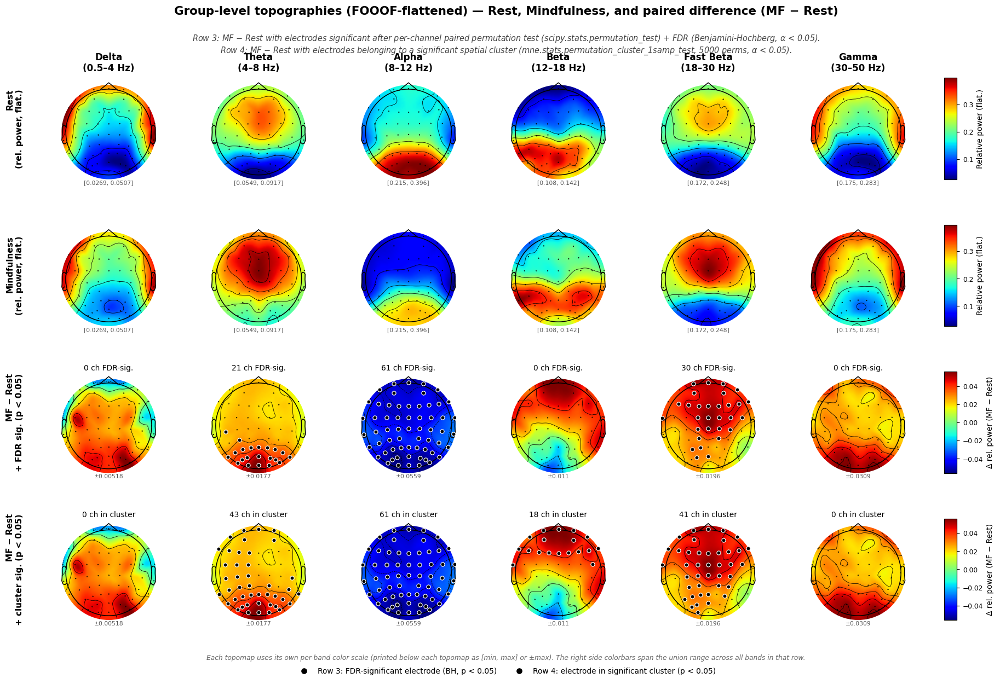

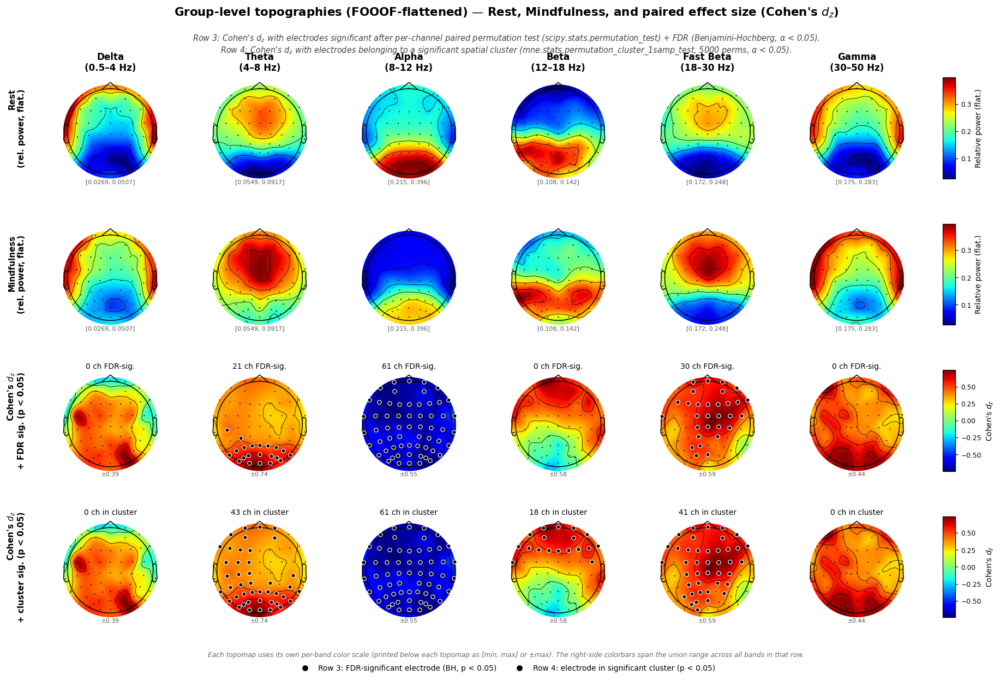

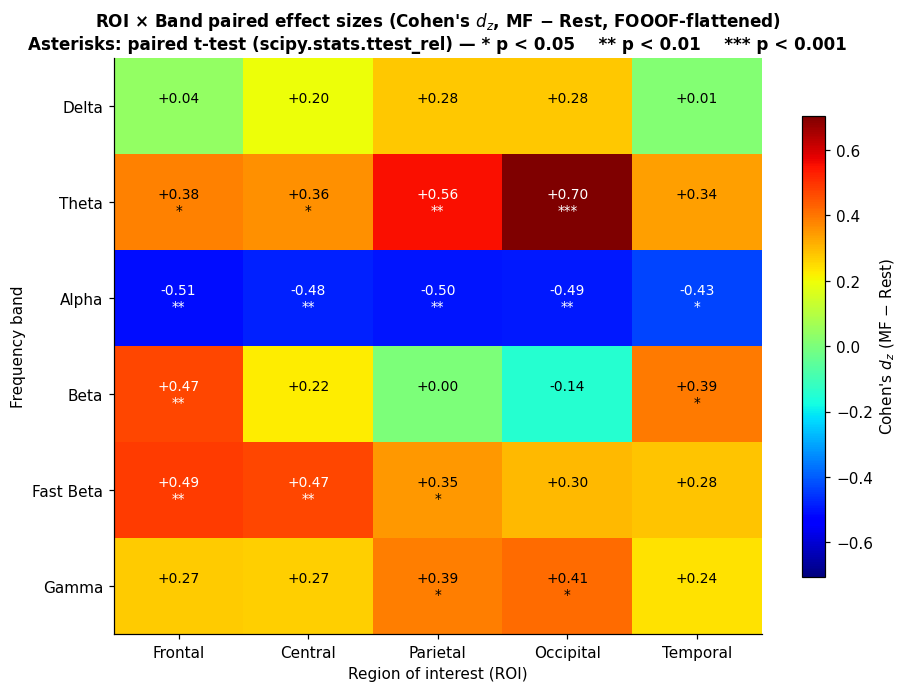

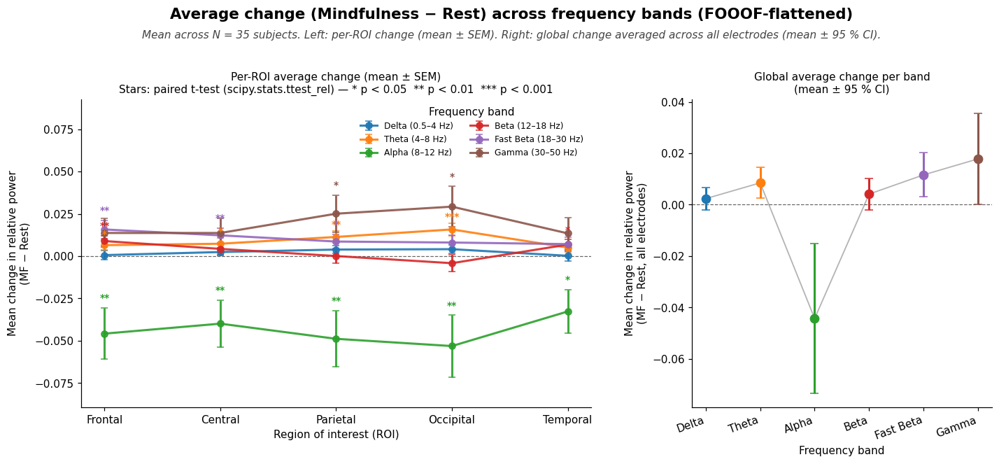

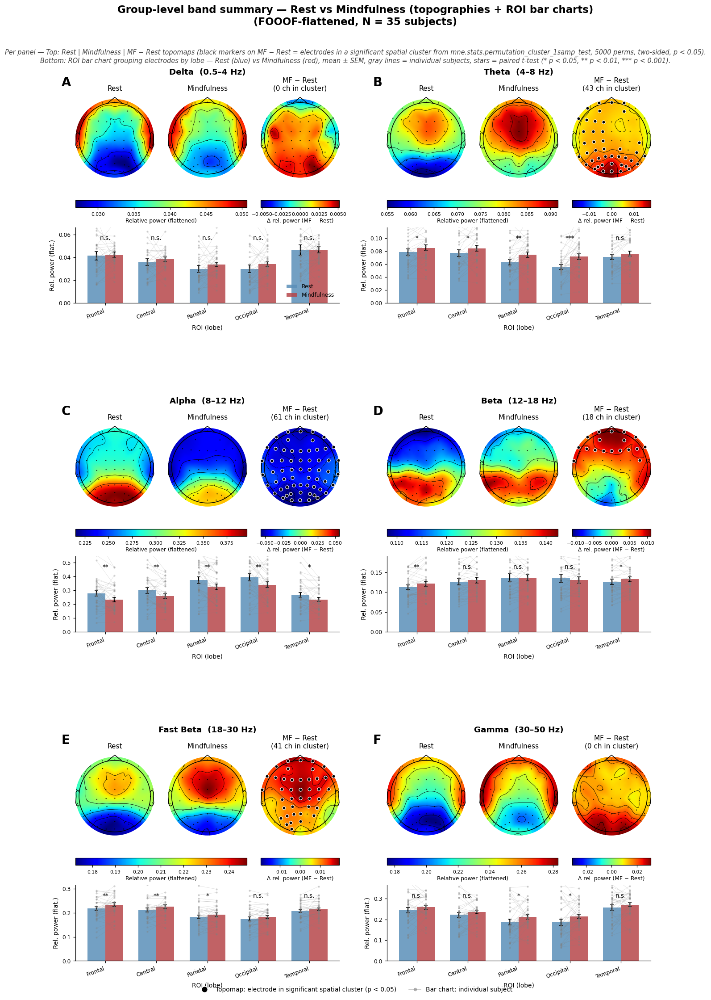

...

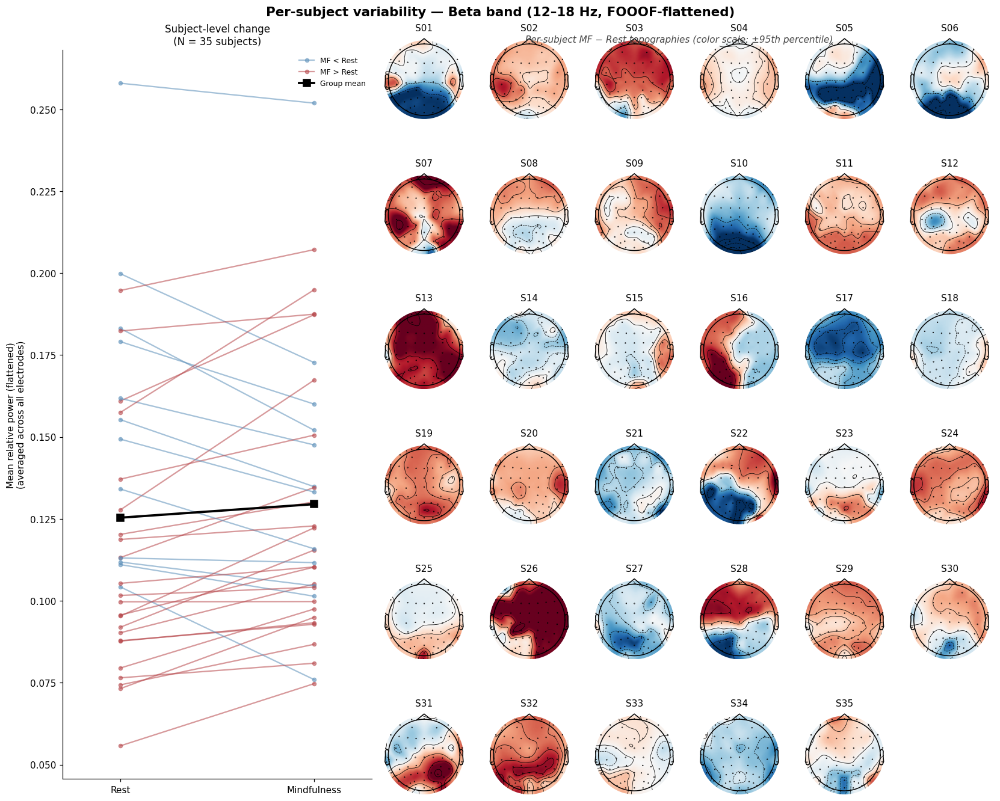

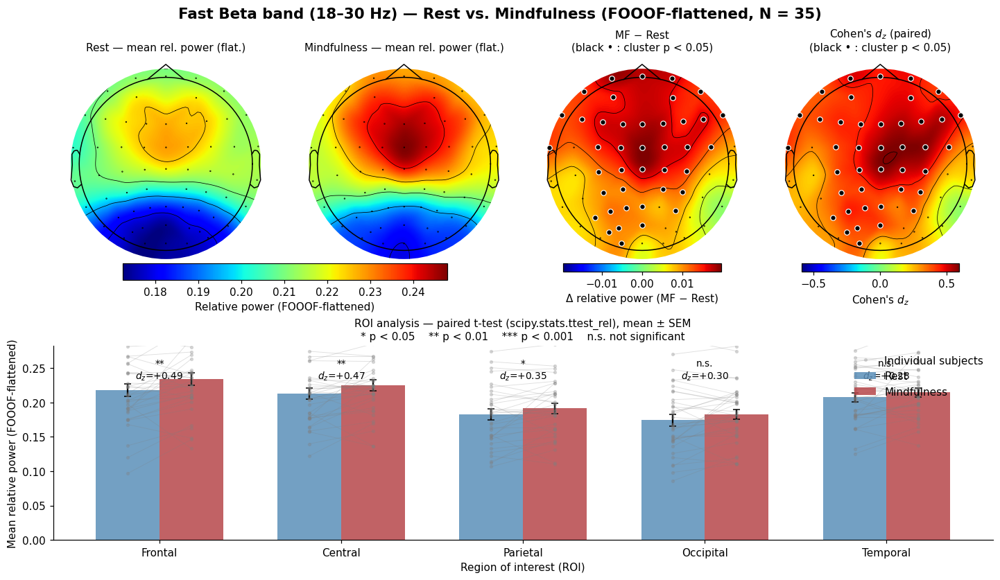

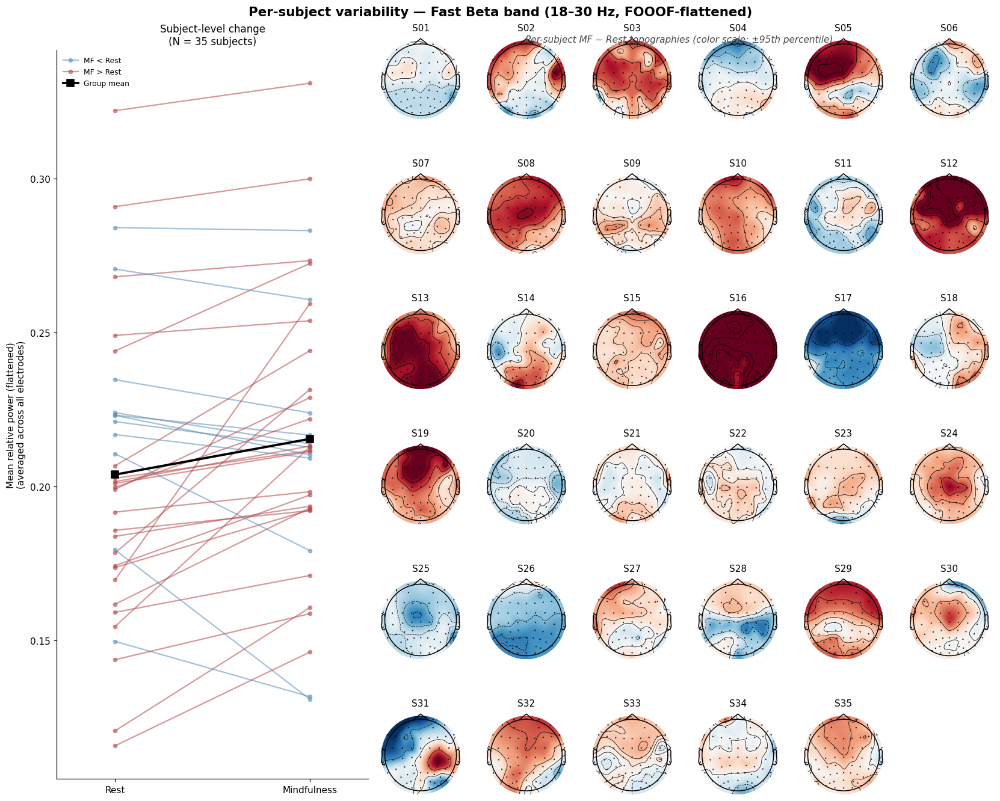

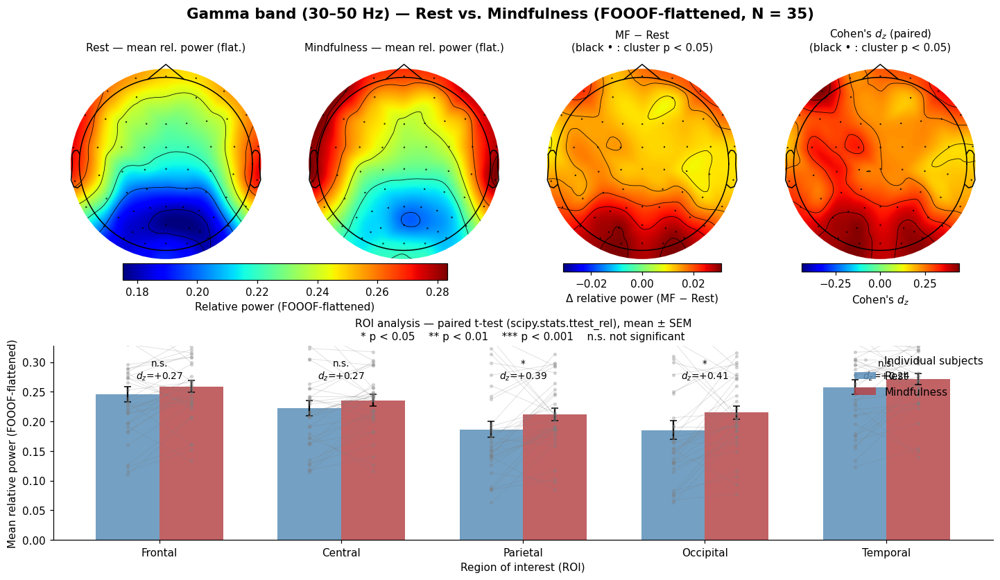

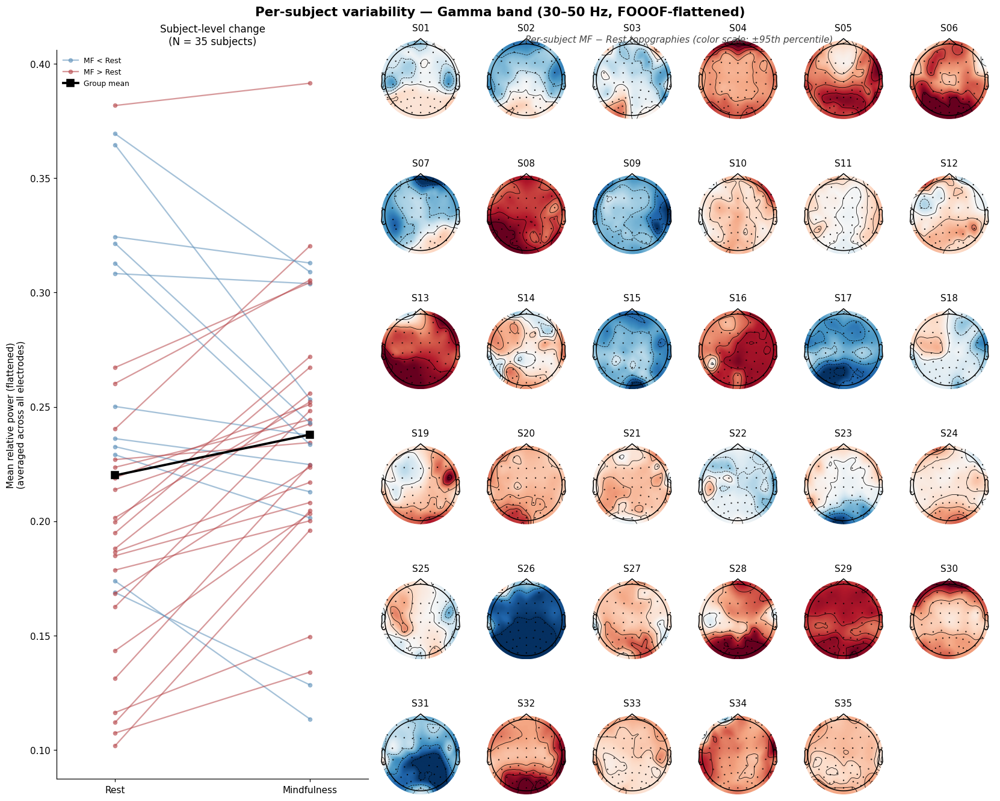

In [ ]:
"""
Group-level EEG analysis: Rest vs. Mindfulness  (FOOOF-flattened version)
=========================================================================

Same pipeline as the non-FOOOF version, but the PSD is flattened with
FOOOF / specparam (aperiodic 1/f component removed) BEFORE relative-power
normalization.

Includes:
  1. Effect sizes (Cohen's d_z for paired data) per band/electrode
  2. Cluster-based permutation test (spatial) via MNE
  3. ROI analysis (frontal / central / parietal / occipital / temporal)
  4. Individual-subject variability plots
  5. Publication-ready plotting:
       - cleaner layout, perceptually uniform colormap (jet for diff, jet for power)
       - one summary figure per band
       - bar plots per band with individual-subject lines
       - consistent typography and spacing
       - NEW: one big ROI analysis figure (all bands, difference only)
  6. Automatic generation of a methods/figures log (figures_methods.txt)
     that documents how each figure and statistical result was produced,
     including the exact function names and libraries used.

Author: improved version (FOOOF flattening added; full-ROI figure added)
"""

from __future__ import annotations

import os
import warnings
from dataclasses import dataclass, field
from datetime import datetime
from typing import Dict, List, Optional, Sequence, Tuple

import matplotlib as mpl
import matplotlib.pyplot as plt
import mne
import numpy as np
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize, TwoSlopeNorm
from mne.stats import permutation_cluster_1samp_test
from scipy.stats import false_discovery_control, permutation_test, ttest_rel, wilcoxon

# FOOOF / specparam: we only use the *initial aperiodic fit* to flatten
# the spectrum (no peak fitting). Try the new specparam package first;
# fall back to legacy fooof. gen_aperiodic reconstructs the aperiodic
# component from its parameters.
try:
    from fooof import FOOOF
    from fooof.sim.gen import gen_aperiodic
    _FOOOF_BACKEND = "fooof"
except ImportError:  # pragma: no cover
    from specparam import SpectralModel as FOOOF  # type: ignore
    from specparam.sim.gen import gen_aperiodic    # type: ignore
    _FOOOF_BACKEND = "specparam"

# -----------------------------------------------------------------------------
# Global plotting style
# -----------------------------------------------------------------------------
mpl.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "legend.frameon": False,
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

FREQUENCY_BANDS: Dict[str, Tuple[float, float]] = {
    "Delta":     (0.5,  4),
    "Theta":     (4,    8),
    "Alpha":     (8,   12),
    "Beta":      (12,  18),
    "Fast Beta": (18,  30),
    "Gamma":     (30,  50),
}

# Standard 10-20 ROI definitions. Channels not in `info` are silently dropped.
ROI_DEFINITIONS: Dict[str, List[str]] = {
    "Frontal":   ["Fp1", "Fp2", "F7", "F3", "Fz", "F4", "F8", "AF3", "AF4"],
    "Central":   ["FC5", "FC1", "FC2", "FC6", "C3", "Cz", "C4", "CP5", "CP1", "CP2", "CP6"],
    "Parietal":  ["P7", "P3", "Pz", "P4", "P8", "PO3", "PO4"],
    "Occipital": ["O1", "Oz", "O2"],
    "Temporal":  ["T7", "T8", "FT7", "FT8", "TP7", "TP8"],
}

# FOOOF defaults — minimal kwargs since we only use the *initial* aperiodic fit
# (no peak fitting). 'aperiodic_mode' is the main knob: 'fixed' for a pure
# exponent + offset, 'knee' if a clear knee is present in the fit range.
FOOOF_DEFAULTS = dict(
    aperiodic_mode="fixed",
)


# =============================================================================
# FOOOF flattening (initial aperiodic fit only, no peak fitting)
# =============================================================================
def _flatten_psd_with_fooof(
    psd: np.ndarray,                # (n_epochs, n_channels, n_freqs), linear power
    freqs: np.ndarray,
    fooof_kwargs: Dict,
    fit_range: Tuple[float, float],
    verbose: bool = False,
) -> np.ndarray:
    """
    Remove only the *initial aperiodic component* of a PSD using FOOOF.

    This is the cheap FOOOF flattening step: we ONLY call the first-pass
    robust aperiodic fit (`FOOOF._robust_ap_fit`) and subtract it. No peak
    fitting is performed because the goal is just a flattened spectrum, not
    peak parameters.

    Per spectrum, in FOOOF's log10-power space:
        init_ap_params = fm._robust_ap_fit(fm.freqs, fm.power_spectrum)
        init_ap_fit    = gen_aperiodic(fm.freqs, init_ap_params)
        init_flat_spec = fm.power_spectrum - init_ap_fit

    The flattened spectrum is returned in LINEAR power
        flat_psd = 10 ** init_flat_spec
    so the downstream pipeline (np.trapezoid, relative-power normalization)
    works unchanged.

    Frequencies outside the fit range keep their original PSD values; band
    integrations only use bins inside the fit range. Spectra with a failed
    fit fall back to the original PSD and are counted (verbose-mode warning).
    """
    n_epochs, n_channels, n_freqs = psd.shape
    flat = np.empty_like(psd)

    fmask = (freqs >= fit_range[0]) & (freqs <= fit_range[1])
    if fmask.sum() < 5:
        raise ValueError(
            f"FOOOF fit range {fit_range} contains too few frequency bins "
            f"({fmask.sum()}). Widen fit_range or increase PSD resolution."
        )

    n_fail_total = 0

    # One FOOOF object reused across all spectra (we only need _robust_ap_fit).
    fm = FOOOF(**fooof_kwargs, verbose=False)

    for ep in range(n_epochs):
        for ch in range(n_channels):
            spec = psd[ep, ch]
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")
                    fm.add_data(freqs, spec, fit_range)
                    init_ap_params = fm._robust_ap_fit(fm.freqs, fm.power_spectrum)
                    init_ap_fit    = gen_aperiodic(fm.freqs, init_ap_params)
                    init_flat_spec = fm.power_spectrum - init_ap_fit

                if np.any(~np.isfinite(init_flat_spec)):
                    raise RuntimeError("non-finite flattened spectrum")

                # Back to linear power.
                flat_in = np.power(10.0, init_flat_spec)
                # Keep original outside fit range; flattened inside.
                flat[ep, ch] = spec.copy()
                flat[ep, ch, fmask] = flat_in
            except Exception as e:
                n_fail_total += 1
                flat[ep, ch] = spec
                if verbose:
                    print(f"    FOOOF fail (ep={ep}, ch={ch}): {e}")

    if n_fail_total and verbose:
        print(f"    FOOOF: {n_fail_total} / {n_epochs * n_channels} "
              f"spectra fell back to original")

    return flat


# =============================================================================
# Methods logger
# =============================================================================
class MethodsLogger:
    """
    Accumulates a human-readable log describing how each figure and
    statistical result was generated. Writes out a single .txt file.
    """

    def __init__(self):
        self.header_lines: List[str] = []
        self.entries: List[str] = []

    def set_header(self, **params):
        self.header_lines = [
            "=" * 78,
            "EEG group analysis (FOOOF-flattened) — Figure generation & methods log",
            "=" * 78,
            f"Generated:        {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}",
            f"MNE-Python:       {mne.__version__}",
            f"NumPy:            {np.__version__}",
            f"FOOOF backend:    {_FOOOF_BACKEND}",
            "",
            "Analysis parameters",
            "-" * 78,
        ]
        for k, v in params.items():
            self.header_lines.append(f"  {k:20s} = {v}")
        self.header_lines.append("")

    def add(self, title: str, lines: List[str]):
        block = [
            "=" * 78,
            title,
            "=" * 78,
        ]
        block.extend(lines)
        block.append("")
        self.entries.append("\n".join(block))

    def write(self, path: str):
        with open(path, "w", encoding="utf-8") as f:
            f.write("\n".join(self.header_lines))
            f.write("\n")
            f.write("\n".join(self.entries))
        print(f"  Methods log saved to: {os.path.abspath(path)}")


# =============================================================================
# Data loading & PSD computation
# =============================================================================
@dataclass
class GroupPSD:
    """Container for group-level PSD data.

    Two representations are stored per subject:

    1) `psd_R`, `psd_MF` (n_subj, n_ch, n_freqs):
       Subject-level mean PSD spectra. When load_group_psd was called with
       use_fooof=True the spectra are FOOOF-flattened; when relative=True
       each subject's spectrum is the across-epoch mean of the per-epoch
       normalized PSDs (per-epoch ratio of spectrum to total, averaged
       across epochs). These are used for topomaps / plotting.

    2) `band_power_R`, `band_power_MF` (dict[band] -> (n_subj, n_ch)):
       Subject-level mean relative-band-power values, computed as the
       per-epoch ratio
            band_power[epoch] / total_power[epoch]
       averaged across epochs at the very end. This is the "mean of
       ratios" definition of relative band power; all band-level
       statistics (ROI analysis, permutation tests, ROI heatmap, line
       plots) use these values.

    The mean-of-ratios values in (2) are the canonical statistical
    measure; (1) is kept for topomap visualization of the average
    (FOOOF-flattened, normalized) spectrum.
    """
    psd_R:  np.ndarray              # (n_subjects, n_channels, n_freqs)
    psd_MF: np.ndarray              # (n_subjects, n_channels, n_freqs)
    freqs:  np.ndarray              # (n_freqs,)
    info:   mne.Info
    subject_ids: List[str] = field(default_factory=list)
    # Mean-of-ratios relative band power, per band, per (subject, channel).
    band_power_R:  Dict[str, np.ndarray] = field(default_factory=dict)
    band_power_MF: Dict[str, np.ndarray] = field(default_factory=dict)
    # Per-subject mean total power (absolute units, after FOOOF flattening)
    # per channel.
    total_R:  Optional[np.ndarray] = None      # (n_subjects, n_channels)
    total_MF: Optional[np.ndarray] = None      # (n_subjects, n_channels)

    @property
    def n_subjects(self) -> int:
        return self.psd_R.shape[0]

    @property
    def n_channels(self) -> int:
        return self.psd_R.shape[1]

    def band_power(self, band: str, condition: str = "R", relative: bool = True) -> np.ndarray:
        """Return (n_subjects, n_channels) relative band power for a given condition.

        Uses the mean-of-ratios definition: for each (subject, channel),
        the value is the across-epoch mean of
            np.trapezoid(PSD over band range) / np.trapezoid(PSD over [fmin, fmax])
        i.e. each epoch's relative contribution is computed first (on the
        FOOOF-flattened PSD when use_fooof=True), then averaged across
        epochs. The `relative` argument is kept for backward compatibility
        and is ignored — these values are always relative.

        Fallback: if band_power_R / band_power_MF were not populated (e.g.
        the GroupPSD was built manually), integrate the stored
        subject-level mean spectrum over the band range. This recovers the
        same numerical result by linearity of np.trapezoid and np.mean.
        """
        bp = self.band_power_R if condition == "R" else self.band_power_MF
        if band in bp:
            return bp[band]
        # Fallback path for manually-constructed GroupPSDs.
        fmin, fmax = FREQUENCY_BANDS[band]
        idx = np.logical_and(self.freqs >= fmin, self.freqs <= fmax)
        psd = self.psd_R if condition == "R" else self.psd_MF
        return np.trapezoid(psd[:, :, idx], x=self.freqs[idx], axis=2)


def load_group_psd(
    file_pairs: Sequence[Tuple[str, str]],
    fmin: float = 0.5,
    fmax: float = 50.0,
    relative: bool = True,
    psd_method: str = "multitaper",
    use_fooof: bool = True,
    fooof_fit_range: Optional[Tuple[float, float]] = None,
    fooof_kwargs: Optional[Dict] = None,
    verbose: bool = True,
) -> Tuple[GroupPSD, Dict]:
    """
    Load all subjects, compute PSD per epoch, optionally flatten with FOOOF
    (remove the 1/f aperiodic component), then compute relative band power
    as the per-epoch ratio averaged across epochs (mean-of-ratios).
    """
    fooof_kwargs = {**FOOOF_DEFAULTS, **(fooof_kwargs or {})}
    if fooof_fit_range is None:
        fooof_fit_range = (max(fmin, 1.0), fmax)

    psd_R_list, psd_MF_list, ids = [], [], []
    bp_R_per_band: Dict[str, List[np.ndarray]] = {b: [] for b in FREQUENCY_BANDS}
    bp_MF_per_band: Dict[str, List[np.ndarray]] = {b: [] for b in FREQUENCY_BANDS}
    total_R_list:  List[np.ndarray] = []
    total_MF_list: List[np.ndarray] = []
    info, freqs = None, None
    band_idx_cache: Dict[str, np.ndarray] = {}

    if verbose and use_fooof:
        print(f"  FOOOF backend: {_FOOOF_BACKEND}")
        print(f"  FOOOF fit range: "
              f"{fooof_fit_range[0]:.2f}–{fooof_fit_range[1]:.2f} Hz")
        print(f"  FOOOF kwargs: {fooof_kwargs}")

    for i, (f_R, f_MF) in enumerate(file_pairs):
        sid = f"S{i + 1:02d}"
        if verbose:
            print(f"[{sid}] Loading {os.path.basename(f_R)} / {os.path.basename(f_MF)}")
        try:
            ep_R  = mne.read_epochs(f_R,  preload=True, verbose="ERROR")
            ep_MF = mne.read_epochs(f_MF, preload=True, verbose="ERROR")
        except Exception as e:
            print(f"  ! skipped ({e})")
            continue

        psd_R_obj  = ep_R.compute_psd(method=psd_method,  fmin=fmin, fmax=fmax, verbose="ERROR")
        psd_MF_obj = ep_MF.compute_psd(method=psd_method, fmin=fmin, fmax=fmax, verbose="ERROR")

        psd_R,  freqs = psd_R_obj.get_data(return_freqs=True)
        psd_MF, _     = psd_MF_obj.get_data(return_freqs=True)

        # ---- FOOOF flattening (per epoch, per channel) ----
        if use_fooof:
            if verbose:
                print(f"  [{sid}] FOOOF flattening "
                      f"(R: {psd_R.shape}, MF: {psd_MF.shape})")
            psd_R  = _flatten_psd_with_fooof(
                psd_R,  freqs, fooof_kwargs, fooof_fit_range, verbose=verbose)
            psd_MF = _flatten_psd_with_fooof(
                psd_MF, freqs, fooof_kwargs, fooof_fit_range, verbose=verbose)

        # Build band-frequency masks once.
        if not band_idx_cache:
            for b, (lo, hi) in FREQUENCY_BANDS.items():
                band_idx_cache[b] = (freqs >= lo) & (freqs <= hi)

        # ---- Per-epoch total power over [fmin, fmax] ----
        total_R_per_epoch  = np.trapezoid(psd_R,  x=freqs, axis=2)
        total_MF_per_epoch = np.trapezoid(psd_MF, x=freqs, axis=2)

        # Guard against zero/negative totals (can happen with FOOOF flattening).
        safe_total_R  = np.where(total_R_per_epoch  > 0, total_R_per_epoch,  np.nan)
        safe_total_MF = np.where(total_MF_per_epoch > 0, total_MF_per_epoch, np.nan)

        # ---- Per-epoch band power and per-epoch ratio, then mean over epochs ----
        for band, idx in band_idx_cache.items():
            band_R_per_epoch  = np.trapezoid(psd_R[:, :, idx],  x=freqs[idx], axis=2)
            band_MF_per_epoch = np.trapezoid(psd_MF[:, :, idx], x=freqs[idx], axis=2)
            if relative:
                rel_R_per_epoch  = band_R_per_epoch  / safe_total_R
                rel_MF_per_epoch = band_MF_per_epoch / safe_total_MF
            else:
                rel_R_per_epoch  = band_R_per_epoch
                rel_MF_per_epoch = band_MF_per_epoch
            bp_R_per_band[band].append(np.nanmean(rel_R_per_epoch,  axis=0))
            bp_MF_per_band[band].append(np.nanmean(rel_MF_per_epoch, axis=0))

        # ---- Subject-level mean PSD spectrum (for topomap plots) ----
        if relative:
            psd_R_norm  = psd_R  / safe_total_R[:, :, np.newaxis]
            psd_MF_norm = psd_MF / safe_total_MF[:, :, np.newaxis]
            psd_R_list.append(np.nanmean(psd_R_norm,  axis=0))
            psd_MF_list.append(np.nanmean(psd_MF_norm, axis=0))
        else:
            psd_R_list.append(np.nanmean(psd_R,  axis=0))
            psd_MF_list.append(np.nanmean(psd_MF, axis=0))

        # ---- Per-subject mean total power (after flattening) ----
        total_R_list.append(np.nanmean(safe_total_R,  axis=0))
        total_MF_list.append(np.nanmean(safe_total_MF, axis=0))

        ids.append(sid)
        if info is None:
            info = ep_R.info

    if not psd_R_list:
        raise RuntimeError("No subjects loaded successfully.")

    band_power_R  = {b: np.stack(vs) for b, vs in bp_R_per_band.items()}
    band_power_MF = {b: np.stack(vs) for b, vs in bp_MF_per_band.items()}

    group = GroupPSD(
        psd_R=np.stack(psd_R_list),
        psd_MF=np.stack(psd_MF_list),
        freqs=freqs,
        info=info,
        subject_ids=ids,
        band_power_R=band_power_R,
        band_power_MF=band_power_MF,
        total_R=np.stack(total_R_list),
        total_MF=np.stack(total_MF_list),
    )
    settings = {
        "use_fooof":        use_fooof,
        "fooof_backend":    _FOOOF_BACKEND,
        "fooof_fit_range":  fooof_fit_range,
        "fooof_kwargs":     fooof_kwargs,
        "relative":         relative,
        "psd_method":       psd_method,
        "fmin":             fmin,
        "fmax":             fmax,
    }
    return group, settings


# =============================================================================
# Statistics
# =============================================================================
def cohens_dz(x: np.ndarray, y: np.ndarray, axis: int = 0) -> np.ndarray:
    """
    Paired-samples Cohen's d_z = mean(diff) / sd(diff).
    Returns effect size with same shape as the reduced axis.
    """
    diff = x - y
    sd = np.std(diff, axis=axis, ddof=1)
    sd = np.where(sd == 0, np.nan, sd)
    return np.mean(diff, axis=axis) / sd


def permutation_per_channel(
    band_R: np.ndarray,        # (n_subj, n_ch)
    band_MF: np.ndarray,       # (n_subj, n_ch)
    n_permutations: int = 5000,
    alpha: float = 0.01,
    seed: int = 42,
) -> Dict[str, np.ndarray]:
    """Per-electrode paired permutation test on (MF - R) using
    `scipy.stats.permutation_test` with `permutation_type='samples'`
    (paired sign-flip permutation). Multiple-comparison correction
    across channels is performed with the Benjamini-Hochberg FDR procedure
    via `scipy.stats.false_discovery_control(method='bh')`."""
    n_ch = band_R.shape[1]
    p_vals = np.zeros(n_ch)

    def mean_diff(x, y):
        return np.mean(x - y)

    for ch in range(n_ch):
        res = permutation_test(
            data=(band_MF[:, ch], band_R[:, ch]),
            statistic=mean_diff,
            permutation_type="samples",
            n_resamples=n_permutations,
            alternative="two-sided",
            random_state=seed,
        )
        p_vals[ch] = res.pvalue

    p_fdr = false_discovery_control(p_vals, method="bh")
    return {
        "p":            p_vals,
        "p_fdr":        p_fdr,
        "sig":          p_vals < alpha,
        "sig_fdr":      p_fdr  < alpha,
        "dz":           cohens_dz(band_MF, band_R, axis=0),
    }


def cluster_permutation_spatial(
    band_R: np.ndarray,
    band_MF: np.ndarray,
    info: mne.Info,
    n_permutations: int = 5000,
    alpha: float = 0.01,
    seed: int = 42,
) -> Dict[str, np.ndarray]:
    """
    Spatial cluster-based permutation test on the paired difference (MF - R)
    using `mne.stats.permutation_cluster_1samp_test`. Channel adjacency is
    estimated with `mne.channels.find_ch_adjacency(ch_type='eeg')`. Two-sided
    test (`tail=0`). Returns t-statistics, cluster masks, and cluster p-values.
    """
    diff = band_MF - band_R                                  # (n_subj, n_ch)
    adjacency, _ = mne.channels.find_ch_adjacency(info, ch_type="eeg")

    t_obs, clusters, p_clusters, _ = permutation_cluster_1samp_test(
        diff,
        n_permutations=n_permutations,
        adjacency=adjacency,
        tail=0,                       # two-sided
        seed=seed,
        out_type="mask",
        verbose="ERROR",
    )

    sig_cluster = np.zeros(diff.shape[1], dtype=bool)
    for cl, p in zip(clusters, p_clusters):
        if p < alpha:
            sig_cluster |= cl

    return {
        "t_obs":         t_obs,
        "clusters":      clusters,
        "p_clusters":    p_clusters,
        "sig_cluster":   sig_cluster,
    }


def roi_analysis(
    group: GroupPSD,
    rois: Dict[str, List[str]] = ROI_DEFINITIONS,
) -> Dict[str, Dict[str, Dict[str, float]]]:
    """
    Per-ROI, per-band paired stats.
    Returns nested dict: results[band][roi] = {mean_R, mean_MF, dz, t, p, p_wilcoxon}.
    Uses `scipy.stats.ttest_rel` (parametric paired t-test) and
    `scipy.stats.wilcoxon` (non-parametric paired test).
    """
    ch_names = group.info["ch_names"]
    name_to_idx = {ch: i for i, ch in enumerate(ch_names)}

    out: Dict[str, Dict[str, Dict[str, float]]] = {}
    for band in FREQUENCY_BANDS:
        out[band] = {}
        bp_R  = group.band_power(band, "R")     # (n_subj, n_ch)
        bp_MF = group.band_power(band, "MF")

        for roi, chans in rois.items():
            idx = [name_to_idx[c] for c in chans if c in name_to_idx]
            if not idx:
                continue
            roi_R  = bp_R[:, idx].mean(axis=1)
            roi_MF = bp_MF[:, idx].mean(axis=1)

            t, p_t = ttest_rel(roi_MF, roi_R)
            try:
                _, p_w = wilcoxon(roi_MF, roi_R)
            except ValueError:
                p_w = np.nan

            out[band][roi] = {
                "n_channels": len(idx),
                "mean_R":  float(roi_R.mean()),
                "mean_MF": float(roi_MF.mean()),
                "diff":    float((roi_MF - roi_R).mean()),
                "dz":      float(cohens_dz(roi_MF, roi_R)),
                "t":       float(t),
                "p":       float(p_t),
                "p_wilcoxon": float(p_w) if not np.isnan(p_w) else np.nan,
                "subj_R":  roi_R,
                "subj_MF": roi_MF,
            }
    return out


def band_contribution_table(
    group: GroupPSD,
    aggregate: str = "mean",
) -> Dict[str, np.ndarray]:
    """
    Per-electrode table of relative-power contribution per band per state.
    (See full docstring in the original file — unchanged behavior.)
    """
    assert aggregate in ("mean", "median")
    agg = np.nanmean if aggregate == "mean" else np.nanmedian

    bands = list(FREQUENCY_BANDS.keys())
    states = ["Rest", "MF"]
    ch_names = list(group.info["ch_names"])

    band_columns: List[Tuple[str, str]] = []
    column_labels: List[str] = []
    cols: List[np.ndarray] = []
    for band in bands:
        for state in states:
            cond_key = "R" if state == "Rest" else "MF"
            bp = group.band_power(band, cond_key)          # (n_subj, n_ch)
            cols.append(agg(bp, axis=0))                   # (n_ch,)
            band_columns.append((band, state))
            column_labels.append(f"{band}_{state}")

    values = np.stack(cols, axis=1)                        # (n_ch, n_bands*2)

    # Sum columns: single np.trapezoid integral over the UNION of band ranges.
    union_lo = min(lo for (lo, _) in FREQUENCY_BANDS.values())
    union_hi = max(hi for (_, hi) in FREQUENCY_BANDS.values())
    idx = (group.freqs >= union_lo) & (group.freqs <= union_hi)
    f_sub = group.freqs[idx]

    def sum_over_union(condition: str) -> np.ndarray:
        cond_key = "R" if condition == "Rest" else "MF"
        psd = group.psd_R if cond_key == "R" else group.psd_MF
        per_subj = np.trapezoid(psd[:, :, idx], x=f_sub, axis=2)   # (n_subj, n_ch)
        return agg(per_subj, axis=0)                                # (n_ch,)

    sum_rest = sum_over_union("Rest")[:, None]
    sum_mf   = sum_over_union("MF")[:, None]
    delta    = sum_mf - sum_rest

    values_full = np.concatenate([values, sum_rest, sum_mf, delta], axis=1)
    column_labels_full = column_labels + ["Sum_Rest", "Sum_MF", "DeltaSum_MF-Rest"]

    return {
        "electrode":      np.array(ch_names),
        "columns":        column_labels_full,
        "values":         values_full,
        "band_columns":   band_columns,
        "sum_freq_range": (float(union_lo), float(union_hi)),
        "aggregate":      aggregate,
    }


def save_band_contribution_table(
    table: Dict[str, np.ndarray],
    out_path: str,
    fmt: str = "csv",
    float_fmt: str = "%.6f",
) -> str:
    """Save the band-contribution table to disk."""
    assert fmt in ("csv", "tsv", "markdown")
    header = ["electrode"] + table["columns"]

    if fmt in ("csv", "tsv"):
        sep = "," if fmt == "csv" else "\t"
        lines = [sep.join(header)]
        for i, ch in enumerate(table["electrode"]):
            row = [ch] + [float_fmt % v for v in table["values"][i]]
            lines.append(sep.join(row))
        with open(out_path, "w", encoding="utf-8") as f:
            f.write("\n".join(lines))
            f.write("\n")
    else:  # markdown
        widths = [max(len(h), 10) for h in header]
        def fmt_row(cells):
            return "| " + " | ".join(c.ljust(w) for c, w in zip(cells, widths)) + " |"
        sep_row = "| " + " | ".join("-" * w for w in widths) + " |"
        lines = [fmt_row(header), sep_row]
        for i, ch in enumerate(table["electrode"]):
            row = [ch] + [float_fmt % v for v in table["values"][i]]
            lines.append(fmt_row(row))
        with open(out_path, "w", encoding="utf-8") as f:
            f.write("\n".join(lines))
            f.write("\n")

    return os.path.abspath(out_path)


# =============================================================================
# Plotting helpers
# =============================================================================
def _add_sig_markers(ax, info, mask, color="black", marker="o", size=18):
    """Add markers at significant electrode positions on a topomap axis."""
    if mask.sum() == 0:
        return
    pos = np.array([
        mne.channels.layout._find_topomap_coords(info, picks=[ch])[0]
        for ch in np.where(mask)[0]
    ])
    ax.scatter(
        pos[:, 0], pos[:, 1],
        s=size, marker=marker,
        facecolors=color, edgecolors="white", linewidths=0.8,
        zorder=10,
    )


def _topomap(data, info, ax, *, cmap="jet", vlim=(None, None),
             title=None, contours=4):
    """Thin wrapper for consistent topomap styling."""
    im, _ = mne.viz.plot_topomap(
        data, info, axes=ax, cmap=cmap, vlim=vlim,
        contours=contours, sensors=True, outlines="head",
        show=False,
    )
    if title:
        ax.set_title(title, fontsize=10, pad=4)
    return im


def _plot_overview_4rows(
    group: GroupPSD,
    stats_per_band: Dict[str, Dict[str, np.ndarray]],
    cluster_per_band: Dict[str, Dict[str, np.ndarray]],
    metric: str,                       # "diff" or "dz"
    save_path: Optional[str] = None,
    alpha_cluster: float = 0.01,
    alpha_fdr: float = 0.05,
    n_permutations: int = 5000,
):
    """Shared helper for the 4-row overview figures."""
    assert metric in ("diff", "dz")
    bands = list(FREQUENCY_BANDS.keys())
    n_rows, n_cols = 4, len(bands)

    fig = plt.figure(figsize=(2.6 * n_cols + 1.8, 2.6 * n_rows + 1.0))
    gs = fig.add_gridspec(
        n_rows, n_cols + 1,
        width_ratios=[1.0] * n_cols + [0.10],
        hspace=0.45, wspace=0.20,
        left=0.06, right=0.93, top=0.88, bottom=0.09,
    )
    axes = np.empty((n_rows, n_cols), dtype=object)
    for r in range(n_rows):
        for c in range(n_cols):
            axes[r, c] = fig.add_subplot(gs[r, c])
    cax_axes = [fig.add_subplot(gs[r, n_cols]) for r in range(n_rows)]

    if metric == "diff":
        main_title = ("Group-level topographies (FOOOF-flattened) — Rest, "
                      "Mindfulness, and paired difference (MF − Rest)")
        effect_label_short = "MF − Rest"
        effect_label_full = "Δ rel. power (MF − Rest)"
    else:
        main_title = ("Group-level topographies (FOOOF-flattened) — Rest, "
                      "Mindfulness, and paired effect size (Cohen's $d_z$)")
        effect_label_short = "Cohen's $d_z$"
        effect_label_full = "Cohen's $d_z$"

    fig.suptitle(main_title, fontsize=14, fontweight="bold", y=0.985)
    fig.text(
        0.5, 0.945,
        f"Row 3: {effect_label_short} with electrodes significant after "
        f"per-channel paired permutation test (scipy.stats.permutation_test) "
        f"+ FDR (Benjamini-Hochberg, $\\alpha$ < {alpha_fdr}).\n"
        f"Row 4: {effect_label_short} with electrodes belonging to a "
        f"significant spatial cluster "
        f"(mne.stats.permutation_cluster_1samp_test, "
        f"{n_permutations} perms, $\\alpha$ < {alpha_cluster}).",
        ha="center", va="top", fontsize=9.5, style="italic", color="#444444",
    )

    row_titles = [
        "Rest\n(rel. power, flat.)",
        "Mindfulness\n(rel. power, flat.)",
        f"{effect_label_short}\n+ FDR sig. (p < {alpha_fdr})",
        f"{effect_label_short}\n+ cluster sig. (p < {alpha_cluster})",
    ]
    for r, t in enumerate(row_titles):
        axes[r, 0].text(-0.40, 0.5, t, transform=axes[r, 0].transAxes,
                        fontsize=10, fontweight="bold",
                        ha="right", va="center", rotation=90)

    row_ranges: List[Tuple[float, float]] = []
    row_diverging = [False, False, True, True]

    for c, band in enumerate(bands):
        bp_R  = group.band_power(band, "R").mean(axis=0)
        bp_MF = group.band_power(band, "MF").mean(axis=0)
        diff  = bp_MF - bp_R
        dz    = stats_per_band[band]["dz"]
        cl    = cluster_per_band[band]
        sig_fdr = stats_per_band[band]["sig_fdr"]

        if metric == "diff":
            effect = diff
            vmax_eff = max(abs(diff.min()), abs(diff.max())) or 1e-12
        else:
            effect = dz
            vmax_eff = max(abs(np.nanmin(dz)), abs(np.nanmax(dz))) or 1e-12

        vmax_pow = max(bp_R.max(), bp_MF.max())
        vmin_pow = min(bp_R.min(), bp_MF.min())

        fmin_b, fmax_b = FREQUENCY_BANDS[band]
        axes[0, c].set_title(f"{band}\n({fmin_b}–{fmax_b} Hz)",
                             fontsize=11, fontweight="bold", pad=8)

        _topomap(bp_R,  group.info, axes[0, c], cmap="jet",
                 vlim=(vmin_pow, vmax_pow))
        _topomap(bp_MF, group.info, axes[1, c], cmap="jet",
                 vlim=(vmin_pow, vmax_pow))

        _topomap(effect, group.info, axes[2, c], cmap="jet",
                 vlim=(-vmax_eff, vmax_eff))
        _add_sig_markers(axes[2, c], group.info, sig_fdr,
                         color="black", marker="o", size=22)
        axes[2, c].set_title(f"{int(sig_fdr.sum())} ch FDR-sig.",
                             fontsize=9, pad=2)

        _topomap(effect, group.info, axes[3, c], cmap="jet",
                 vlim=(-vmax_eff, vmax_eff))
        _add_sig_markers(axes[3, c], group.info, cl["sig_cluster"],
                         color="black", marker="o", size=22)
        axes[3, c].set_title(f"{int(cl['sig_cluster'].sum())} ch in cluster",
                             fontsize=9, pad=2)

        axes[0, c].set_xlabel(f"[{vmin_pow:.3g}, {vmax_pow:.3g}]",
                              fontsize=7, color="#555555", labelpad=1)
        axes[1, c].set_xlabel(f"[{vmin_pow:.3g}, {vmax_pow:.3g}]",
                              fontsize=7, color="#555555", labelpad=1)
        eff_fmt = f"±{vmax_eff:.3g}" if metric == "diff" else f"±{vmax_eff:.2f}"
        axes[2, c].set_xlabel(eff_fmt, fontsize=7, color="#555555", labelpad=1)
        axes[3, c].set_xlabel(eff_fmt, fontsize=7, color="#555555", labelpad=1)

        if c == 0:
            row_ranges = [(vmin_pow, vmax_pow),
                          (vmin_pow, vmax_pow),
                          (-vmax_eff, vmax_eff),
                          (-vmax_eff, vmax_eff)]
        else:
            row_ranges[0] = (min(row_ranges[0][0], vmin_pow),
                             max(row_ranges[0][1], vmax_pow))
            row_ranges[1] = (min(row_ranges[1][0], vmin_pow),
                             max(row_ranges[1][1], vmax_pow))
            row_ranges[2] = (-max(abs(row_ranges[2][0]), vmax_eff),
                              max(abs(row_ranges[2][1]), vmax_eff))
            row_ranges[3] = (-max(abs(row_ranges[3][0]), vmax_eff),
                              max(abs(row_ranges[3][1]), vmax_eff))

    row_labels = [
        "Relative power (flat.)",
        "Relative power (flat.)",
        effect_label_full,
        effect_label_full,
    ]
    for cax, (vmin, vmax), label, diverging in zip(
            cax_axes, row_ranges, row_labels, row_diverging):
        if diverging:
            v = max(abs(vmin), abs(vmax))
            norm = Normalize(vmin=-v, vmax=v)
        else:
            norm = Normalize(vmin=vmin, vmax=vmax)
        sm = ScalarMappable(norm=norm, cmap="jet")
        sm.set_array([])
        cb = fig.colorbar(sm, cax=cax)
        cb.set_label(label, fontsize=9)
        cb.ax.tick_params(labelsize=8)

    fig.text(
        0.5, 0.030,
        "Each topomap uses its own per-band color scale (printed below each "
        "topomap as [min, max] or ±max). "
        "The right-side colorbars span the union range across all bands in that row.",
        ha="center", va="bottom", fontsize=8, style="italic", color="#666666",
    )

    from matplotlib.lines import Line2D
    legend_handles = [
        Line2D([0], [0], marker="o", color="w", markerfacecolor="black",
               markeredgecolor="white", markersize=8,
               label=f"Row 3: FDR-significant electrode (BH, p < {alpha_fdr})"),
        Line2D([0], [0], marker="o", color="w", markerfacecolor="black",
               markeredgecolor="white", markersize=8,
               label=f"Row 4: electrode in significant cluster "
                     f"(p < {alpha_cluster})"),
    ]
    fig.legend(handles=legend_handles, loc="lower center",
               ncol=2, fontsize=9, bbox_to_anchor=(0.5, 0.0))

    if save_path:
        fig.savefig(save_path)
    return fig


def plot_overview_diff(
    group: GroupPSD,
    stats_per_band: Dict[str, Dict[str, np.ndarray]],
    cluster_per_band: Dict[str, Dict[str, np.ndarray]],
    save_path: Optional[str] = None,
    alpha_cluster: float = 0.01,
    alpha_fdr: float = 0.05,
    n_permutations: int = 5000,
):
    """4-row overview using the paired difference (MF − Rest) as the effect."""
    return _plot_overview_4rows(
        group, stats_per_band, cluster_per_band,
        metric="diff",
        save_path=save_path,
        alpha_cluster=alpha_cluster,
        alpha_fdr=alpha_fdr,
        n_permutations=n_permutations,
    )


def plot_overview_dz(
    group: GroupPSD,
    stats_per_band: Dict[str, Dict[str, np.ndarray]],
    cluster_per_band: Dict[str, Dict[str, np.ndarray]],
    save_path: Optional[str] = None,
    alpha_cluster: float = 0.01,
    alpha_fdr: float = 0.05,
    n_permutations: int = 5000,
):
    """4-row overview using Cohen's d_z (paired effect size) as the effect."""
    return _plot_overview_4rows(
        group, stats_per_band, cluster_per_band,
        metric="dz",
        save_path=save_path,
        alpha_cluster=alpha_cluster,
        alpha_fdr=alpha_fdr,
        n_permutations=n_permutations,
    )


def plot_band_summary(
    group: GroupPSD,
    band: str,
    stats: Dict[str, np.ndarray],
    cluster: Dict[str, np.ndarray],
    roi_results: Dict[str, Dict[str, float]],
    save_path: Optional[str] = None,
    alpha_cluster: float = 0.01,
    n_permutations: int = 5000,
):
    """Publication-ready single-band figure."""
    bp_R  = group.band_power(band, "R")
    bp_MF = group.band_power(band, "MF")
    mean_R, mean_MF = bp_R.mean(0), bp_MF.mean(0)
    diff = mean_MF - mean_R
    dz = stats["dz"]

    fmin_b, fmax_b = FREQUENCY_BANDS[band]

    fig = plt.figure(figsize=(13, 7.5), constrained_layout=True)
    gs = fig.add_gridspec(2, 4, height_ratios=[1.0, 0.95])

    fig.suptitle(
        f"{band} band ({fmin_b}–{fmax_b} Hz) — Rest vs. Mindfulness "
        f"(FOOOF-flattened, N = {group.n_subjects})",
        fontsize=14, fontweight="bold",
    )

    vmax_pow = max(mean_R.max(), mean_MF.max())
    vmin_pow = min(mean_R.min(), mean_MF.min())
    vmax_d   = max(abs(diff.min()), abs(diff.max())) or 1e-12
    vmax_dz  = max(abs(np.nanmin(dz)), abs(np.nanmax(dz))) or 1e-12

    ax_R   = fig.add_subplot(gs[0, 0])
    ax_MF  = fig.add_subplot(gs[0, 1])
    ax_d   = fig.add_subplot(gs[0, 2])
    ax_dz  = fig.add_subplot(gs[0, 3])

    im0 = _topomap(mean_R,  group.info, ax_R,  cmap="jet",
                   vlim=(vmin_pow, vmax_pow),
                   title="Rest — mean rel. power (flat.)")
    im1 = _topomap(mean_MF, group.info, ax_MF, cmap="jet",
                   vlim=(vmin_pow, vmax_pow),
                   title="Mindfulness — mean rel. power (flat.)")
    im2 = _topomap(diff, group.info, ax_d, cmap="jet",
                   vlim=(-vmax_d, vmax_d),
                   title=f"MF − Rest\n(black • : cluster p < {alpha_cluster})")
    _add_sig_markers(ax_d, group.info, cluster["sig_cluster"],
                     color="black", marker="o", size=24)
    im3 = _topomap(dz, group.info, ax_dz, cmap="jet",
                   vlim=(-vmax_dz, vmax_dz),
                   title=f"Cohen's $d_z$ (paired)\n"
                         f"(black • : cluster p < {alpha_cluster})")
    _add_sig_markers(ax_dz, group.info, cluster["sig_cluster"],
                     color="black", marker="o", size=24)

    fig.colorbar(im0, ax=[ax_R, ax_MF], shrink=0.7, location="bottom",
                 pad=0.02, label="Relative power (FOOOF-flattened)")
    fig.colorbar(im2, ax=ax_d,  shrink=0.7, location="bottom",
                 pad=0.02, label="Δ relative power (MF − Rest)")
    fig.colorbar(im3, ax=ax_dz, shrink=0.7, location="bottom",
                 pad=0.02, label="Cohen's $d_z$")

    # ----- Bottom: ROI bar plot with individual subject lines -----
    ax_roi = fig.add_subplot(gs[1, :])
    rois = list(roi_results.keys())
    x = np.arange(len(rois))
    width = 0.35

    means_R  = [roi_results[r]["mean_R"]  for r in rois]
    means_MF = [roi_results[r]["mean_MF"] for r in rois]
    sems_R   = [roi_results[r]["subj_R"].std(ddof=1)  / np.sqrt(group.n_subjects)
                for r in rois]
    sems_MF  = [roi_results[r]["subj_MF"].std(ddof=1) / np.sqrt(group.n_subjects)
                for r in rois]

    ax_roi.bar(x - width/2, means_R,  width, yerr=sems_R,
               label="Rest",        color="#5B8FB9", alpha=0.85, capsize=3)
    ax_roi.bar(x + width/2, means_MF, width, yerr=sems_MF,
               label="Mindfulness", color="#B6464A", alpha=0.85, capsize=3)

    line_handle = None
    for i, r in enumerate(rois):
        rR  = roi_results[r]["subj_R"]
        rMF = roi_results[r]["subj_MF"]
        for s in range(len(rR)):
            ln, = ax_roi.plot([x[i] - width/2, x[i] + width/2],
                              [rR[s], rMF[s]],
                              color="gray", alpha=0.25, linewidth=0.6,
                              marker="o", markersize=2.5, zorder=2)
            if line_handle is None:
                line_handle = ln
    if line_handle is not None:
        line_handle.set_label("Individual subjects")

    ymax_overall = max(max(means_R), max(means_MF)) * 1.15
    for i, r in enumerate(rois):
        p = roi_results[r]["p"]
        dz_ = roi_results[r]["dz"]
        if p < 0.001:   stars = "***"
        elif p < 0.01:  stars = "**"
        elif p < 0.05:  stars = "*"
        else:           stars = "n.s."
        ax_roi.text(x[i], ymax_overall * 0.98,
                    f"{stars}\n$d_z$={dz_:+.2f}",
                    ha="center", va="top", fontsize=9)

    ax_roi.set_xticks(x)
    ax_roi.set_xticklabels(rois)
    ax_roi.set_ylabel("Mean relative power (FOOOF-flattened)")
    ax_roi.set_xlabel("Region of interest (ROI)")
    ax_roi.set_title(
        "ROI analysis — paired t-test (scipy.stats.ttest_rel), "
        "mean ± SEM\n"
        "* p < 0.05    ** p < 0.01    *** p < 0.001    n.s. not significant",
        fontsize=10,
    )
    ax_roi.legend(loc="upper right")
    ax_roi.set_ylim(0, ymax_overall * 1.05)

    if save_path:
        fig.savefig(save_path)
    return fig


def plot_subject_variability(
    group: GroupPSD,
    band: str,
    save_path: Optional[str] = None,
):
    """Per-subject variability for a single band."""
    bp_R  = group.band_power(band, "R").mean(axis=1)
    bp_MF = group.band_power(band, "MF").mean(axis=1)
    diff_per_subj = group.band_power(band, "MF") - group.band_power(band, "R")

    n_subj = group.n_subjects
    n_cols_topo = 6
    n_rows_topo = int(np.ceil(n_subj / n_cols_topo))

    fmin_b, fmax_b = FREQUENCY_BANDS[band]

    fig = plt.figure(figsize=(15, 3 + 1.5 * n_rows_topo), constrained_layout=True)
    gs = fig.add_gridspec(1, 2, width_ratios=[1.0, 2.0])

    fig.suptitle(
        f"Per-subject variability — {band} band ({fmin_b}–{fmax_b} Hz, "
        f"FOOOF-flattened)",
        fontsize=14, fontweight="bold",
    )

    ax_pair = fig.add_subplot(gs[0, 0])
    up_handle = down_handle = None
    for s in range(n_subj):
        if bp_MF[s] > bp_R[s]:
            color, label = "#B6464A", "MF > Rest"
        else:
            color, label = "#5B8FB9", "MF < Rest"
        ln, = ax_pair.plot([0, 1], [bp_R[s], bp_MF[s]],
                           color=color, alpha=0.55, marker="o", markersize=4)
        if label == "MF > Rest" and up_handle is None:
            up_handle = ln; up_handle.set_label("MF > Rest")
        elif label == "MF < Rest" and down_handle is None:
            down_handle = ln; down_handle.set_label("MF < Rest")
    ax_pair.plot([0, 1], [bp_R.mean(), bp_MF.mean()],
                 color="black", marker="s", markersize=8,
                 linewidth=2.5, label="Group mean", zorder=10)
    ax_pair.set_xticks([0, 1])
    ax_pair.set_xticklabels(["Rest", "Mindfulness"])
    ax_pair.set_ylabel("Mean relative power (flattened)\n"
                       "(averaged across all electrodes)")
    ax_pair.set_title(f"Subject-level change\n(N = {n_subj} subjects)")
    ax_pair.legend(loc="best", fontsize=8)
    ax_pair.set_xlim(-0.3, 1.3)

    gs_right = gs[0, 1].subgridspec(n_rows_topo, n_cols_topo, hspace=0.3, wspace=0.1)
    vmax = np.nanpercentile(np.abs(diff_per_subj), 95) or 1e-12

    last_im = None
    for s in range(n_subj):
        r, c = divmod(s, n_cols_topo)
        ax = fig.add_subplot(gs_right[r, c])
        last_im = _topomap(diff_per_subj[s], group.info, ax,
                           cmap="RdBu_r", vlim=(-vmax, vmax),
                           title=group.subject_ids[s])

    for s in range(n_subj, n_rows_topo * n_cols_topo):
        r, c = divmod(s, n_cols_topo)
        ax = fig.add_subplot(gs_right[r, c])
        ax.axis("off")

    fig.text(0.68, 0.96,
             "Per-subject MF − Rest topographies (color scale: ±95th percentile)",
             ha="center", va="top", fontsize=10, style="italic", color="#444444")

    if save_path:
        fig.savefig(save_path)
    return fig


def plot_roi_heatmap(roi_all: Dict[str, Dict[str, Dict[str, float]]],
                     save_path: Optional[str] = None):
    """Heatmap: rows = bands, cols = ROIs, cell = Cohen's d_z, asterisks = p < .05."""
    bands = list(roi_all.keys())
    rois = list(next(iter(roi_all.values())).keys())

    dz_mat = np.array([[roi_all[b][r]["dz"] for r in rois] for b in bands])
    p_mat  = np.array([[roi_all[b][r]["p"]  for r in rois] for b in bands])

    fig, ax = plt.subplots(figsize=(1.4 * len(rois) + 2.5, 0.8 * len(bands) + 2.0))
    vmax = np.nanmax(np.abs(dz_mat)) or 1e-12
    im = ax.imshow(dz_mat, cmap="jet", vmin=-vmax, vmax=vmax, aspect="auto")

    ax.set_xticks(range(len(rois)))
    ax.set_xticklabels(rois)
    ax.set_yticks(range(len(bands)))
    ax.set_yticklabels(bands)
    ax.set_xlabel("Region of interest (ROI)")
    ax.set_ylabel("Frequency band")
    ax.set_title("ROI × Band paired effect sizes (Cohen's $d_z$, MF − Rest, "
                 "FOOOF-flattened)\n"
                 "Asterisks: paired t-test (scipy.stats.ttest_rel) — "
                 "* p < 0.05    ** p < 0.01    *** p < 0.001",
                 fontweight="bold", fontsize=11)

    for i in range(len(bands)):
        for j in range(len(rois)):
            p = p_mat[i, j]
            if p < 0.001:   star = "***"
            elif p < 0.01:  star = "**"
            elif p < 0.05:  star = "*"
            else:           star = ""
            ax.text(j, i, f"{dz_mat[i, j]:+.2f}\n{star}",
                    ha="center", va="center", fontsize=9,
                    color="white" if abs(dz_mat[i, j]) > vmax * 0.6 else "black")

    fig.colorbar(im, ax=ax, label="Cohen's $d_z$ (MF − Rest)", shrink=0.8)
    if save_path:
        fig.savefig(save_path)
    return fig


def plot_band_change_lines(
    group: GroupPSD,
    roi_all: Dict[str, Dict[str, Dict[str, float]]],
    save_path: Optional[str] = None,
):
    """Average change (MF − Rest) per band as a line plot."""
    bands = list(FREQUENCY_BANDS.keys())
    rois = list(next(iter(roi_all.values())).keys())

    fig, (ax_l, ax_r) = plt.subplots(
        1, 2, figsize=(13, 5.8),
        gridspec_kw=dict(width_ratios=[1.7, 1.0], wspace=0.25),
    )

    fig.suptitle("Average change (Mindfulness − Rest) across frequency bands "
                 "(FOOOF-flattened)",
                 fontsize=14, fontweight="bold", y=0.985)
    fig.text(
        0.5, 0.935,
        f"Mean across N = {group.n_subjects} subjects. "
        f"Left: per-ROI change (mean ± SEM). "
        f"Right: global change averaged across all electrodes (mean ± 95 % CI).",
        ha="center", va="top", fontsize=10, style="italic", color="#444444",
    )

    cmap = plt.get_cmap("tab10")
    band_colors = {b: cmap(i % 10) for i, b in enumerate(bands)}

    x = np.arange(len(rois))
    y_max_abs = 0.0
    for b in bands:
        diffs = np.array([
            roi_all[b][r]["subj_MF"] - roi_all[b][r]["subj_R"]
            for r in rois
        ])
        means = diffs.mean(axis=1)
        sems = diffs.std(axis=1, ddof=1) / np.sqrt(group.n_subjects)
        y_max_abs = max(y_max_abs, np.max(np.abs(means) + sems))

        ax_l.errorbar(
            x, means, yerr=sems,
            label=f"{b} ({FREQUENCY_BANDS[b][0]}–{FREQUENCY_BANDS[b][1]} Hz)",
            color=band_colors[b], marker="o", markersize=6,
            linewidth=2, capsize=3, alpha=0.9,
        )

        for i, r in enumerate(rois):
            p = roi_all[b][r]["p"]
            if p < 0.001:   star = "***"
            elif p < 0.01:  star = "**"
            elif p < 0.05:  star = "*"
            else:           continue
            ax_l.text(x[i], means[i] + sems[i] + y_max_abs * 0.04,
                      star, ha="center", va="bottom",
                      fontsize=9, color=band_colors[b], fontweight="bold")

    ax_l.axhline(0, color="black", linewidth=0.8, linestyle="--", alpha=0.6)
    ax_l.set_xticks(x)
    ax_l.set_xticklabels(rois)
    ax_l.set_xlabel("Region of interest (ROI)")
    ax_l.set_ylabel("Mean change in relative power\n(MF − Rest)")
    ax_l.set_title(
        "Per-ROI average change (mean ± SEM)\n"
        "Stars: paired t-test (scipy.stats.ttest_rel) — "
        "* p < 0.05  ** p < 0.01  *** p < 0.001",
        fontsize=10,
    )
    ax_l.legend(loc="best", fontsize=8, ncol=2, title="Frequency band")
    ax_l.set_ylim(-y_max_abs * 1.25, y_max_abs * 1.30)

    band_means: List[float] = []
    band_ci_lo: List[float] = []
    band_ci_hi: List[float] = []
    for b in bands:
        diff_subj = (group.band_power(b, "MF").mean(axis=1)
                     - group.band_power(b, "R").mean(axis=1))
        m = diff_subj.mean()
        sem = diff_subj.std(ddof=1) / np.sqrt(group.n_subjects)
        ci = 1.96 * sem
        band_means.append(m)
        band_ci_lo.append(m - ci)
        band_ci_hi.append(m + ci)

    xb = np.arange(len(bands))
    ax_r.plot(xb, band_means, color="#444444", linewidth=1.2,
              alpha=0.4, zorder=1)
    for i, b in enumerate(bands):
        ax_r.errorbar(
            xb[i], band_means[i],
            yerr=[[band_means[i] - band_ci_lo[i]],
                  [band_ci_hi[i] - band_means[i]]],
            fmt="o", color=band_colors[b], markersize=8,
            linewidth=2, capsize=4, zorder=3,
        )

    ax_r.axhline(0, color="black", linewidth=0.8, linestyle="--", alpha=0.6)
    ax_r.set_xticks(xb)
    ax_r.set_xticklabels(bands, rotation=20, ha="right")
    ax_r.set_xlabel("Frequency band")
    ax_r.set_ylabel("Mean change in relative power\n(MF − Rest, all electrodes)")
    ax_r.set_title("Global average change per band\n(mean ± 95 % CI)",
                   fontsize=10)

    fig.subplots_adjust(left=0.07, right=0.98, bottom=0.09, top=0.78,
                        wspace=0.30)

    if save_path:
        fig.savefig(save_path)
    return fig


# =============================================================================
# NEW: One big figure with per-band topomaps (Rest, MF, MF - Rest), panels A..F
# =============================================================================
def plot_all_bands_topomaps(
    group: GroupPSD,
    cluster_per_band: Dict[str, Dict[str, np.ndarray]],
    roi_all: Dict[str, Dict[str, Dict[str, float]]],
    save_path: Optional[str] = None,
    alpha_cluster: float = 0.01,
    n_permutations: int = 5000,
    panel_cols: int = 2,
):
    """
    One big figure consolidating the visual content from the per-band
    ``02_band_<BAND>.png`` figures, with one panel per frequency band.

    Each panel is labeled A, B, C, ... and contains:
      Top — three topomaps arranged in a row:
        1. Rest         — group-mean relative band power per electrode.
        2. Mindfulness  — group-mean relative band power per electrode
                          (same color scale as the Rest topomap).
        3. MF − Rest    — paired difference (group mean of MF minus Rest),
                          with black markers at electrodes belonging to a
                          significant spatial cluster from
                          ``mne.stats.permutation_cluster_1samp_test``
                          (two-sided, p < ``alpha_cluster``).
      Bottom — ROI bar chart grouping electrodes by lobe (Frontal, Central,
        Parietal, Occipital, Temporal as defined in ``ROI_DEFINITIONS``):
        Rest (blue) vs Mindfulness (red) mean relative band power per ROI,
        with SEM error bars, individual-subject lines overlaid in gray, and
        significance stars from the paired t-test in ``roi_all``
        (``scipy.stats.ttest_rel`` — * p < 0.05, ** p < 0.01, *** p < 0.001).

    Cohen's d_z is NOT shown anywhere.

    Each panel has its own per-band color scales: Rest and Mindfulness
    share a single power scale (so they are directly comparable within the
    band), and the difference topomap uses an independent symmetric
    diverging scale centered at zero. Compact colorbars are placed under
    the topomap row. The ROI bar chart uses its own per-band y-axis.

    Panels are arranged in a grid with ``panel_cols`` columns (default 2),
    giving a 3 x 2 layout for the default six bands. The panel order is
    the iteration order of ``FREQUENCY_BANDS`` (Delta, Theta, Alpha, Beta,
    Fast Beta, Gamma -> A, B, C, D, E, F).
    """
    bands = list(FREQUENCY_BANDS.keys())
    n_bands = len(bands)
    panel_rows = int(np.ceil(n_bands / panel_cols))
    n_subj = group.n_subjects

    # Pre-compute per-band quantities so panel layout code stays simple.
    panel_data: Dict[str, Dict[str, np.ndarray]] = {}
    for b in bands:
        bp_R  = group.band_power(b, "R")
        bp_MF = group.band_power(b, "MF")
        mean_R, mean_MF = bp_R.mean(0), bp_MF.mean(0)
        diff = mean_MF - mean_R
        vmax_pow = max(mean_R.max(), mean_MF.max())
        vmin_pow = min(mean_R.min(), mean_MF.min())
        vmax_d   = max(abs(diff.min()), abs(diff.max())) or 1e-12
        panel_data[b] = dict(
            mean_R=mean_R, mean_MF=mean_MF, diff=diff,
            vmin_pow=vmin_pow, vmax_pow=vmax_pow, vmax_d=vmax_d,
        )

    # Figure size: each panel now contains topomaps + a bar chart, so
    # increase per-panel height. ~6.0 in wide per panel column, ~6.0 in
    # tall per panel row (topomap row ~3.0 in + bar chart ~2.5 in + padding).
    fig_w = 6.0 * panel_cols + 0.4
    fig_h = 6.0 * panel_rows + 2.6
    fig = plt.figure(figsize=(fig_w, fig_h))

    # Compute top/bottom margins as a fraction of fig_h so the suptitle and
    # subtitle have absolute space that doesn't shrink as panel rows grow.
    # The first row of panels has band titles ~0.45 in above its top axis,
    # so we reserve generous space for the title block.
    top_margin = 1.0 - 2.10 / fig_h          # reserve ~2.10 in for title block
    bot_margin = 0.80 / fig_h                 # reserve ~0.80 in for footer legend

    # Outer grid: one cell per panel, with space between panels.
    outer = fig.add_gridspec(
        panel_rows, panel_cols,
        left=0.04, right=0.985, top=top_margin, bottom=bot_margin,
        hspace=0.55, wspace=0.18,
    )

    fig.suptitle(
        "Group-level band summary — Rest vs Mindfulness "
        "(topographies + ROI bar charts)\n(FOOOF-flattened, "
        f"N = {n_subj} subjects)",
        fontsize=15, fontweight="bold", y=1.0 - 0.35 / fig_h,
    )
    fig.text(
        0.5, 1.0 - 1.25 / fig_h,
        f"Per panel — Top: Rest | Mindfulness | MF − Rest topomaps "
        f"(black markers on MF − Rest = electrodes in a significant spatial "
        f"cluster from mne.stats.permutation_cluster_1samp_test, "
        f"{n_permutations} perms, two-sided, p < {alpha_cluster}).\n"
        f"Bottom: ROI bar chart grouping electrodes by lobe — Rest (blue) vs "
        f"Mindfulness (red), mean ± SEM, gray lines = individual subjects, "
        f"stars = paired t-test (* p < 0.05, ** p < 0.01, *** p < 0.001).",
        ha="center", va="top", fontsize=9.5, style="italic", color="#444444",
    )

    panel_letters = [chr(ord("A") + i) for i in range(n_bands)]

    # Colors matching the per-band summary figures.
    color_rest = "#5B8FB9"
    color_mf   = "#B6464A"

    rois_in_panel = list(next(iter(roi_all.values())).keys())

    for i, band in enumerate(bands):
        r = i // panel_cols
        c = i %  panel_cols
        letter = panel_letters[i]
        d = panel_data[band]
        cl = cluster_per_band[band]
        roi_results = roi_all[band]
        fmin_b, fmax_b = FREQUENCY_BANDS[band]

        # Inner grid for this panel:
        #   row 0: three topomaps
        #   row 1: power colorbar (spans 2 topomap cols) + diff colorbar
        #   row 2: ROI bar chart (spans all 3 topomap columns)
        inner = outer[r, c].subgridspec(
            3, 3,
            height_ratios=[1.0, 0.08, 0.85],
            hspace=0.35, wspace=0.18,
        )
        ax_R  = fig.add_subplot(inner[0, 0])
        ax_MF = fig.add_subplot(inner[0, 1])
        ax_d  = fig.add_subplot(inner[0, 2])
        cax_pow = fig.add_subplot(inner[1, 0:2])
        cax_dif = fig.add_subplot(inner[1, 2])
        ax_roi  = fig.add_subplot(inner[2, 0:3])

        # ---- Topomaps ----
        _topomap(d["mean_R"],  group.info, ax_R,  cmap="jet",
                 vlim=(d["vmin_pow"], d["vmax_pow"]),
                 title="Rest")
        _topomap(d["mean_MF"], group.info, ax_MF, cmap="jet",
                 vlim=(d["vmin_pow"], d["vmax_pow"]),
                 title="Mindfulness")
        _topomap(d["diff"], group.info, ax_d, cmap="jet",
                 vlim=(-d["vmax_d"], d["vmax_d"]),
                 title=f"MF − Rest\n({int(cl['sig_cluster'].sum())} ch in cluster)")
        _add_sig_markers(ax_d, group.info, cl["sig_cluster"],
                         color="black", marker="o", size=22)

        # ---- Panel letter + band title above the topomap row ----
        ax_R.text(
            -0.18, 1.20,
            f"{letter}",
            transform=ax_R.transAxes,
            fontsize=18, fontweight="bold", ha="left", va="top",
        )
        ax_MF.text(
            0.5, 1.20,
            f"{band}  ({fmin_b}–{fmax_b} Hz)",
            transform=ax_MF.transAxes,
            fontsize=12, fontweight="bold", ha="center", va="bottom",
        )

        # ---- Power colorbar (shared by Rest and Mindfulness within this band) ----
        norm_pow = Normalize(vmin=d["vmin_pow"], vmax=d["vmax_pow"])
        sm_pow = ScalarMappable(norm=norm_pow, cmap="jet")
        sm_pow.set_array([])
        cb_pow = fig.colorbar(sm_pow, cax=cax_pow, orientation="horizontal")
        cb_pow.set_label("Relative power (flattened)", fontsize=8, labelpad=2)
        cb_pow.ax.tick_params(labelsize=7)

        # ---- Difference colorbar ----
        norm_dif = Normalize(vmin=-d["vmax_d"], vmax=d["vmax_d"])
        sm_dif = ScalarMappable(norm=norm_dif, cmap="jet")
        sm_dif.set_array([])
        cb_dif = fig.colorbar(sm_dif, cax=cax_dif, orientation="horizontal")
        cb_dif.set_label("Δ rel. power (MF − Rest)", fontsize=8, labelpad=2)
        cb_dif.ax.tick_params(labelsize=7)

        # ---- ROI bar chart (Rest vs Mindfulness, grouped by lobe) ----
        rois = rois_in_panel
        x = np.arange(len(rois))
        width = 0.35

        means_R  = [roi_results[r_]["mean_R"]  for r_ in rois]
        means_MF = [roi_results[r_]["mean_MF"] for r_ in rois]
        sems_R   = [roi_results[r_]["subj_R"].std(ddof=1)  / np.sqrt(n_subj)
                    for r_ in rois]
        sems_MF  = [roi_results[r_]["subj_MF"].std(ddof=1) / np.sqrt(n_subj)
                    for r_ in rois]

        ax_roi.bar(x - width/2, means_R,  width, yerr=sems_R,
                   color=color_rest, alpha=0.85, capsize=2.5,
                   label="Rest")
        ax_roi.bar(x + width/2, means_MF, width, yerr=sems_MF,
                   color=color_mf,   alpha=0.85, capsize=2.5,
                   label="Mindfulness")

        # Individual-subject lines.
        for j, r_ in enumerate(rois):
            rR  = roi_results[r_]["subj_R"]
            rMF = roi_results[r_]["subj_MF"]
            for s in range(n_subj):
                ax_roi.plot(
                    [x[j] - width/2, x[j] + width/2],
                    [rR[s], rMF[s]],
                    color="gray", alpha=0.25, linewidth=0.5,
                    marker="o", markersize=2.0, zorder=2,
                )

        # Significance stars + y-axis headroom.
        bar_top = max(
            max(m + s for m, s in zip(means_R,  sems_R)),
            max(m + s for m, s in zip(means_MF, sems_MF)),
        )
        ymax_band = bar_top * 1.30 if bar_top > 0 else 1e-6
        star_y = bar_top * 1.06
        for j, r_ in enumerate(rois):
            p = roi_results[r_]["p"]
            if p < 0.001:   stars = "***"
            elif p < 0.01:  stars = "**"
            elif p < 0.05:  stars = "*"
            else:           stars = "n.s."
            ax_roi.text(x[j], star_y, stars,
                        ha="center", va="bottom", fontsize=9)

        ax_roi.set_xticks(x)
        ax_roi.set_xticklabels(rois, rotation=20, ha="right", fontsize=9)
        ax_roi.set_ylabel("Rel. power (flat.)", fontsize=9)
        ax_roi.set_xlabel("ROI (lobe)", fontsize=9)
        ax_roi.set_ylim(0, ymax_band)
        ax_roi.tick_params(axis="both", labelsize=8)

        # Legend only on the first panel to avoid clutter. Place it below
        # the bars (lower-right) so it doesn't collide with significance stars
        # which sit above the bars.
        if i == 0:
            ax_roi.legend(loc="lower right", fontsize=8)

    # Footer with the significance-marker legend.
    from matplotlib.lines import Line2D
    legend_handles = [
        Line2D(
            [0], [0], marker="o", color="w", markerfacecolor="black",
            markeredgecolor="white", markersize=9,
            label=f"Topomap: electrode in significant spatial cluster "
                  f"(p < {alpha_cluster})",
        ),
        Line2D(
            [0], [0], color="gray", alpha=0.5, linewidth=1, marker="o",
            markersize=4, label="Bar chart: individual subject",
        ),
    ]
    fig.legend(
        handles=legend_handles, loc="lower center",
        ncol=2, fontsize=9, bbox_to_anchor=(0.5, 0.002),
    )

    if save_path:
        fig.savefig(save_path)
    return fig


# =============================================================================
# NEW: Big full-ROI analysis figure (paired DIFFERENCE only, no Cohen's d_z)
# =============================================================================
def plot_roi_full_analysis(
    group: GroupPSD,
    roi_all: Dict[str, Dict[str, Dict[str, float]]],
    save_path: Optional[str] = None,
):
    """
    One big figure summarizing the COMPLETE ROI analysis using only the
    paired difference (Mindfulness − Rest) as the effect metric.

    Layout: 2 rows x N_bands columns.
      Row 1 (top, per band):
          Grouped bar plot of mean relative power per ROI, Rest (blue) vs.
          Mindfulness (red), with SEM error bars and individual-subject lines
          overlaid. Significance stars above each ROI come from the existing
          paired t-test in `roi_all` (scipy.stats.ttest_rel on MF − Rest).
      Row 2 (bottom, per band):
          Per-ROI paired difference (MF − Rest, mean ± SEM across subjects),
          with a zero reference line. Bars colored by sign of the difference
          (red = positive / MF > Rest, blue = negative / MF < Rest). The mean
          paired difference value (Δ) is annotated above each bar; significance
          stars from the same paired t-test are shown above the annotation.

    No Cohen's d_z anywhere — only mean relative power per state and the
    paired difference between states.
    """
    bands = list(FREQUENCY_BANDS.keys())
    rois = list(next(iter(roi_all.values())).keys())
    n_bands = len(bands)
    n_rois = len(rois)
    n_subj = group.n_subjects

    # Figure size: wide enough for one column per band, tall enough for two rows.
    fig = plt.figure(figsize=(3.4 * n_bands + 1.0, 9.5))
    gs = fig.add_gridspec(
        2, n_bands,
        hspace=0.55, wspace=0.30,
        left=0.05, right=0.985, top=0.88, bottom=0.08,
    )

    fig.suptitle(
        "ROI analysis — Rest vs. Mindfulness across all frequency bands "
        "(FOOOF-flattened)",
        fontsize=15, fontweight="bold", y=0.975,
    )
    fig.text(
        0.5, 0.935,
        f"N = {n_subj} subjects. "
        f"Top row: mean relative power per ROI for Rest (blue) and Mindfulness "
        f"(red), error bars = SEM, gray lines = individual subjects.   "
        f"Bottom row: paired difference (MF − Rest) per ROI, error bars = SEM.   "
        f"Stars: paired t-test (scipy.stats.ttest_rel) — "
        f"* p < 0.05  ** p < 0.01  *** p < 0.001.",
        ha="center", va="top", fontsize=10, style="italic", color="#444444",
    )

    # --- Pass 1: collect per-band data for shared y-axis scaling ---
    bar_means_R:   Dict[str, List[float]] = {}
    bar_means_MF:  Dict[str, List[float]] = {}
    bar_sems_R:    Dict[str, List[float]] = {}
    bar_sems_MF:   Dict[str, List[float]] = {}
    diff_means:    Dict[str, np.ndarray] = {}
    diff_sems:     Dict[str, np.ndarray] = {}
    subj_R_all:    Dict[str, List[np.ndarray]] = {}
    subj_MF_all:   Dict[str, List[np.ndarray]] = {}

    # Global y-range for the bottom row (so band-to-band magnitudes are comparable)
    global_diff_abs = 0.0
    # Global y-max for the top row (purely cosmetic; per-band y-axes also OK).
    # We use band-specific top-row scaling to preserve readability, since
    # mean relative power varies strongly across bands (Delta ≫ Gamma).

    for b in bands:
        rR_list  = [roi_all[b][r]["subj_R"]  for r in rois]
        rMF_list = [roi_all[b][r]["subj_MF"] for r in rois]
        bar_means_R[b]  = [arr.mean() for arr in rR_list]
        bar_means_MF[b] = [arr.mean() for arr in rMF_list]
        bar_sems_R[b]   = [arr.std(ddof=1) / np.sqrt(n_subj) for arr in rR_list]
        bar_sems_MF[b]  = [arr.std(ddof=1) / np.sqrt(n_subj) for arr in rMF_list]
        subj_R_all[b]   = rR_list
        subj_MF_all[b]  = rMF_list

        # Paired difference per ROI (MF - Rest), mean and SEM across subjects.
        diffs_per_roi = np.array([
            rMF_list[i] - rR_list[i] for i in range(n_rois)
        ])  # (n_rois, n_subj)
        dm   = diffs_per_roi.mean(axis=1)
        dsem = diffs_per_roi.std(axis=1, ddof=1) / np.sqrt(n_subj)
        diff_means[b] = dm
        diff_sems[b]  = dsem
        global_diff_abs = max(
            global_diff_abs,
            float(np.max(np.abs(dm) + dsem)) if dm.size else 0.0,
        )

    if global_diff_abs == 0.0:
        global_diff_abs = 1e-12

    # Sign-based colors for the difference bars.
    color_pos = "#B6464A"   # MF > Rest (red)
    color_neg = "#5B8FB9"   # MF < Rest (blue)
    color_rest = "#5B8FB9"
    color_mf   = "#B6464A"

    x = np.arange(n_rois)
    width = 0.35

    for c, b in enumerate(bands):
        fmin_b, fmax_b = FREQUENCY_BANDS[b]

        # =========================================================
        # TOP: grouped bar plot of mean relative power per ROI
        # =========================================================
        ax_top = fig.add_subplot(gs[0, c])

        ax_top.bar(x - width / 2, bar_means_R[b],  width,
                   yerr=bar_sems_R[b],
                   color=color_rest, alpha=0.85, capsize=2.5,
                   label="Rest")
        ax_top.bar(x + width / 2, bar_means_MF[b], width,
                   yerr=bar_sems_MF[b],
                   color=color_mf,   alpha=0.85, capsize=2.5,
                   label="Mindfulness")

        # Individual-subject lines for each ROI
        for i in range(n_rois):
            rR  = subj_R_all[b][i]
            rMF = subj_MF_all[b][i]
            for s in range(n_subj):
                ax_top.plot(
                    [x[i] - width / 2, x[i] + width / 2],
                    [rR[s], rMF[s]],
                    color="gray", alpha=0.22, linewidth=0.5,
                    marker="o", markersize=2.0, zorder=2,
                )

        # Significance stars above each ROI (paired t-test from roi_all).
        # Reserve generous headroom so they don't overlap the legend.
        bar_top = max(
            max(m + s for m, s in zip(bar_means_R[b],  bar_sems_R[b])),
            max(m + s for m, s in zip(bar_means_MF[b], bar_sems_MF[b])),
        )
        ymax_band = bar_top * 1.35 if bar_top > 0 else 1e-6
        star_y = bar_top * 1.08
        for i, r in enumerate(rois):
            p = roi_all[b][r]["p"]
            if p < 0.001:   stars = "***"
            elif p < 0.01:  stars = "**"
            elif p < 0.05:  stars = "*"
            else:           stars = "n.s."
            ax_top.text(x[i], star_y, stars,
                        ha="center", va="bottom", fontsize=9)

        ax_top.set_xticks(x)
        ax_top.set_xticklabels(rois, rotation=25, ha="right", fontsize=9)
        ax_top.set_title(f"{b}\n({fmin_b}–{fmax_b} Hz)",
                         fontsize=11, fontweight="bold", pad=6)
        if c == 0:
            ax_top.set_ylabel("Mean relative power\n(FOOOF-flattened)")
        ax_top.set_ylim(0, ymax_band)

        # Legend only in the first column, anchored to upper-left to avoid the stars.
        if c == 0:
            ax_top.legend(loc="upper left", fontsize=8)

        # =========================================================
        # BOTTOM: per-ROI paired difference (MF - Rest)
        # =========================================================
        ax_bot = fig.add_subplot(gs[1, c])
        dm   = diff_means[b]
        dsem = diff_sems[b]

        bar_colors = [color_pos if v >= 0 else color_neg for v in dm]
        ax_bot.bar(x, dm, width=0.65, yerr=dsem,
                   color=bar_colors, alpha=0.85, capsize=3,
                   edgecolor="black", linewidth=0.5)

        ax_bot.axhline(0, color="black", linewidth=0.9,
                       linestyle="--", alpha=0.6)

        # Annotate each bar with Δ value + significance stars.
        # Labels are placed at fixed offsets near the top/bottom of the panel
        # so they don't collide with each other or with nearby small bars.
        ylim_top    =  global_diff_abs * 1.45
        ylim_bottom = -global_diff_abs * 1.45
        for i, r in enumerate(rois):
            p = roi_all[b][r]["p"]
            if p < 0.001:   stars = "***"
            elif p < 0.01:  stars = "**"
            elif p < 0.05:  stars = "*"
            else:           stars = ""
            label = f"Δ={dm[i]:+.2g}"
            if stars:
                label = f"{stars}\n{label}"
            # Positive bars: label near top of panel. Negative bars: label near bottom.
            if dm[i] >= 0:
                label_y = ylim_top * 0.92
                va = "top"
            else:
                label_y = ylim_bottom * 0.92
                va = "bottom"
            ax_bot.text(x[i], label_y, label,
                        ha="center", va=va, fontsize=7.5,
                        color="#222222",
                        linespacing=1.0)

        ax_bot.set_xticks(x)
        ax_bot.set_xticklabels(rois, rotation=25, ha="right", fontsize=9)
        if c == 0:
            ax_bot.set_ylabel("Paired difference\n(MF − Rest), mean ± SEM")
        # Shared symmetric y-limits across bands so magnitudes are comparable.
        ax_bot.set_ylim(-global_diff_abs * 1.45, global_diff_abs * 1.45)
        ax_bot.set_xlabel("ROI", fontsize=9)

    # Footer note explaining the bottom-row scaling and color encoding
    fig.text(
        0.5, 0.020,
        "Bottom row: bars colored by sign of the mean difference "
        "(red = MF > Rest, blue = MF < Rest). "
        "All bottom-row panels share the same symmetric y-axis so band-to-band "
        "magnitudes are directly comparable.",
        ha="center", va="bottom", fontsize=8.5, style="italic", color="#666666",
    )

    if save_path:
        fig.savefig(save_path)
    return fig


# =============================================================================
# Top-level driver
# =============================================================================
def run_full_analysis(
    file_pairs: Sequence[Tuple[str, str]],
    out_dir: str = "figures",
    fmin: float = 0.5,
    fmax: float = 50.0,
    n_permutations: int = 5000,
    alpha: float = 0.01,
    relative: bool = True,
    psd_method: str = "multitaper",
    use_fooof: bool = True,
    fooof_fit_range: Optional[Tuple[float, float]] = None,
    fooof_kwargs: Optional[Dict] = None,
):
    os.makedirs(out_dir, exist_ok=True)
    logger = MethodsLogger()

    # -------------------------------------------------------------------------
    print("=" * 70)
    print("STEP 1/4: Loading data, computing PSDs, FOOOF flattening")
    print("=" * 70)
    group, settings = load_group_psd(
        file_pairs, fmin=fmin, fmax=fmax,
        relative=relative, psd_method=psd_method,
        use_fooof=use_fooof,
        fooof_fit_range=fooof_fit_range,
        fooof_kwargs=fooof_kwargs,
    )
    print(f"  -> Loaded {group.n_subjects} subjects, {group.n_channels} channels, "
          f"{len(group.freqs)} freqs ({group.freqs[0]:.1f}–{group.freqs[-1]:.1f} Hz)")

    logger.set_header(
        out_dir=os.path.abspath(out_dir),
        fmin_Hz=fmin,
        fmax_Hz=fmax,
        psd_method=psd_method,
        relative_power=relative,
        use_fooof=use_fooof,
        fooof_backend=settings["fooof_backend"],
        fooof_fit_range=settings["fooof_fit_range"],
        fooof_kwargs=settings["fooof_kwargs"],
        n_permutations=n_permutations,
        alpha=alpha,
        n_file_pairs=len(file_pairs),
        n_subjects_loaded=group.n_subjects,
        frequency_bands=", ".join(f"{b} ({lo}-{hi} Hz)"
                                  for b, (lo, hi) in FREQUENCY_BANDS.items()),
        ROIs=", ".join(f"{r}({len(ch)} ch)" for r, ch in ROI_DEFINITIONS.items()),
    )

    logger.add(
        "STEP 1 — Data loading, PSD computation & FOOOF flattening",
        [
            f"Function:           load_group_psd()",
            f"Subjects loaded:    {group.n_subjects} / {len(file_pairs)} requested",
            f"Channels:           {group.n_channels}",
            f"Frequency range:    {group.freqs[0]:.2f}–{group.freqs[-1]:.2f} Hz "
            f"({len(group.freqs)} bins)",
            "",
            "Pipeline per subject (mean-of-ratios relative power on "
            "FOOOF-flattened PSD):",
            "  1. Epochs are read with mne.read_epochs() for both Rest (_R) "
            "and Mindfulness (_MF) recordings.",
            f"  2. PSD is computed per epoch with "
            f"mne.Epochs.compute_psd(method='{psd_method}', "
            f"fmin={fmin}, fmax={fmax}).",
            "     Shape: (n_epochs, n_channels, n_freqs).",
            "",
            "  3. FOOOF / specparam aperiodic (1/f) removal "
            "— _flatten_psd_with_fooof():",
            "     Only the initial aperiodic component is removed (no peak fitting).",
            f"     Backend: '{settings['fooof_backend']}', "
            f"fit range {settings['fooof_fit_range'][0]:.2f}–"
            f"{settings['fooof_fit_range'][1]:.2f} Hz, "
            f"kwargs {settings['fooof_kwargs']}.",
            "",
            "  4. Per-epoch total and band-power integrals via numpy.trapezoid.",
            "  5. " + ("Relative power (per-epoch ratio averaged across epochs)."
                      if relative else "Absolute power (no normalization)."),
            "  6. Subject-level mean spectrum stored for topomap plotting only;",
            "     band statistics use the mean-of-ratios values from step 5.",
        ],
    )

    # -------------------------------------------------------------------------
    print("\n" + "=" * 70)
    print("STEP 2/4: Per-channel + cluster-based permutation tests")
    print("=" * 70)
    stats_per_band: Dict[str, Dict[str, np.ndarray]] = {}
    cluster_per_band: Dict[str, Dict[str, np.ndarray]] = {}
    band_stat_lines: List[str] = []
    for band in FREQUENCY_BANDS:
        bp_R  = group.band_power(band, "R")
        bp_MF = group.band_power(band, "MF")

        stats_per_band[band]   = permutation_per_channel(
            bp_R, bp_MF, n_permutations=n_permutations, alpha=alpha)
        cluster_per_band[band] = cluster_permutation_spatial(
            bp_R, bp_MF, group.info, n_permutations=n_permutations, alpha=alpha)

        s = stats_per_band[band]
        c = cluster_per_band[band]
        line = (f"  {band:9s}  uncorr={s['sig'].sum():2d}  "
                f"FDR={s['sig_fdr'].sum():2d}  "
                f"cluster={c['sig_cluster'].sum():2d}  "
                f"|dz|max={np.nanmax(np.abs(s['dz'])):.2f}")
        print(line)
        band_stat_lines.append(line)

    logger.add(
        "STEP 2 — Statistical testing (per channel & cluster-based)",
        [
            "Per-channel paired permutation test "
            "(scipy.stats.permutation_test, permutation_type='samples')",
            "FDR correction with scipy.stats.false_discovery_control(method='bh').",
            "Spatial cluster test with mne.stats.permutation_cluster_1samp_test,",
            "adjacency from mne.channels.find_ch_adjacency.",
            f"n_permutations = {n_permutations}, alpha = {alpha}, two-sided.",
            "",
            "Per-band summary (significant channels):",
        ] + band_stat_lines,
    )

    # -------------------------------------------------------------------------
    print("\n" + "=" * 70)
    print("STEP 3/4: ROI analysis")
    print("=" * 70)
    roi_all = roi_analysis(group)
    roi_lines: List[str] = []
    for band, rois in roi_all.items():
        for r, st in rois.items():
            sig = "*" if st["p"] < 0.05 else " "
            line = (f"  {sig} {band:9s} {r:9s}  "
                    f"R={st['mean_R']:.4f}  MF={st['mean_MF']:.4f}  "
                    f"dz={st['dz']:+.3f}  t={st['t']:+.2f}  "
                    f"p={st['p']:.4f}  p_wilcoxon={st['p_wilcoxon']:.4f}")
            print(line)
            roi_lines.append(line)

    logger.add(
        "STEP 3 — ROI analysis",
        [
            "Function:           roi_analysis()",
            "ROI definitions (10-20 system):",
            *[f"  {r:10s} -> {', '.join(ch)}" for r, ch in ROI_DEFINITIONS.items()],
            "",
            "Per band x ROI: scipy.stats.ttest_rel and scipy.stats.wilcoxon "
            "(paired), Cohen's d_z = mean(diff) / sd(diff).",
            "",
            "Per-band, per-ROI results "
            "('*' marks p < 0.05 in the parametric t-test):",
        ] + roi_lines,
    )

    # -------------------------------------------------------------------------
    print("\n" + "=" * 70)
    print("STEP 3b/4: Per-electrode band-contribution table "
          "(FOOOF-flattened)")
    print("=" * 70)
    contrib_table = band_contribution_table(group, aggregate="mean")
    contrib_csv = os.path.join(out_dir, "band_contributions_per_electrode.csv")
    contrib_md  = os.path.join(out_dir, "band_contributions_per_electrode.md")
    save_band_contribution_table(contrib_table, contrib_csv, fmt="csv")
    save_band_contribution_table(contrib_table, contrib_md,  fmt="markdown")
    print(f"  Saved: {contrib_csv}")
    print(f"  Saved: {contrib_md}")

    sum_rest_col = contrib_table["columns"].index("Sum_Rest")
    sum_mf_col   = contrib_table["columns"].index("Sum_MF")
    delta_col    = contrib_table["columns"].index("DeltaSum_MF-Rest")
    summary_lines: List[str] = []
    summary_lines.append("  Electrode-level sum of FOOOF-flattened band "
                         "contributions (mean across subjects):")
    summary_lines.append(f"  {'Electrode':<10s}  {'Sum_Rest':>10s}  "
                         f"{'Sum_MF':>10s}  {'Δ (MF-Rest)':>14s}")
    for i, ch in enumerate(contrib_table["electrode"]):
        v = contrib_table["values"][i]
        line = (f"  {ch:<10s}  {v[sum_rest_col]:10.4f}  "
                f"{v[sum_mf_col]:10.4f}  {v[delta_col]:+14.5f}")
        print(line)
        summary_lines.append(line)

    logger.add(
        "STEP 3b — Per-electrode band-contribution table (FOOOF-flattened)",
        [
            "Function:           band_contribution_table() + "
            "save_band_contribution_table().",
            "Output files:",
            f"  {contrib_csv}",
            f"  {contrib_md}",
            "",
        ] + summary_lines,
    )

    # -------------------------------------------------------------------------
    print("\n" + "=" * 70)
    print("STEP 4/4: Generating figures")
    print("=" * 70)
    fig_overview_diff = os.path.join(out_dir, "00a_overview_diff.png")
    plot_overview_diff(
        group, stats_per_band, cluster_per_band,
        save_path=fig_overview_diff,
        alpha_cluster=alpha,
        alpha_fdr=alpha,
        n_permutations=n_permutations,
    )
    logger.add(
        "FIGURE 00a_overview_diff.png — Group topographies "
        "(effect = paired difference)",
        [
            f"File:               {fig_overview_diff}",
            "Generator:          plot_overview_diff()",
            "4-row topomap overview: Rest, Mindfulness, MF − Rest + FDR-significant,",
            "MF − Rest + cluster-significant electrodes. See main docstring for details.",
        ],
    )

    fig_overview_dz = os.path.join(out_dir, "00b_overview_dz.png")
    plot_overview_dz(
        group, stats_per_band, cluster_per_band,
        save_path=fig_overview_dz,
        alpha_cluster=alpha,
        alpha_fdr=alpha,
        n_permutations=n_permutations,
    )
    logger.add(
        "FIGURE 00b_overview_dz.png — Group topographies "
        "(effect = Cohen's d_z)",
        [
            f"File:               {fig_overview_dz}",
            "Generator:          plot_overview_dz()",
            "Same 4-row layout as 00a, but with Cohen's d_z as the effect in rows 3 and 4.",
        ],
    )

    fig_heatmap = os.path.join(out_dir, "01_roi_heatmap.png")
    plot_roi_heatmap(roi_all, save_path=fig_heatmap)
    logger.add(
        "FIGURE 01_roi_heatmap.png — ROI x Band effect-size heatmap",
        [
            f"File:               {fig_heatmap}",
            "Generator:          plot_roi_heatmap()",
            "Heatmap of Cohen's d_z (rows = bands, cols = ROIs) with t-test stars.",
        ],
    )

    fig_change = os.path.join(out_dir, "01b_band_change_lines.png")
    plot_band_change_lines(group, roi_all, save_path=fig_change)
    logger.add(
        "FIGURE 01b_band_change_lines.png — Average change per band (line plot)",
        [
            f"File:               {fig_change}",
            "Generator:          plot_band_change_lines()",
            "Per-ROI and global mean change (MF − Rest) per band, with SEM and 95 % CI.",
        ],
    )

    # ---- NEW figure: all-bands topomaps (Rest, MF, MF - Rest) + ROI bar charts ----
    fig_all_topo = os.path.join(out_dir, "02_all_bands_topomaps.png")
    plot_all_bands_topomaps(
        group, cluster_per_band, roi_all,
        save_path=fig_all_topo,
        alpha_cluster=alpha,
        n_permutations=n_permutations,
    )
    logger.add(
        "FIGURE 02_all_bands_topomaps.png — All-bands summary "
        "(topomaps + ROI bar charts; panels A..F)",
        [
            f"File:               {fig_all_topo}",
            "Generator:          plot_all_bands_topomaps()",
            "Purpose:            Consolidates the visual content of the "
            "individual 02_band_<BAND>.png",
            "                    figures into a single multi-panel figure. "
            "Each panel is a",
            "                    self-contained band summary. Cohen's d_z "
            "is intentionally",
            "                    OMITTED — only Rest, Mindfulness, the "
            "paired difference, and",
            "                    the lobe-grouped ROI bar chart are shown.",
            "",
            "Layout:             One panel per frequency band, labeled A, B, "
            "C, ... in the order",
            "                    of FREQUENCY_BANDS (A=Delta, B=Theta, "
            "C=Alpha, D=Beta,",
            "                    E=Fast Beta, F=Gamma). Panels are arranged "
            "in a 3 x 2 grid",
            "                    (rows x cols) by default; controlled by "
            "the panel_cols argument.",
            "",
            "Per-panel content (top to bottom):",
            "  Top — three topomaps in a row:",
            "    1. Rest:        group-mean relative band power per "
            "electrode (jet colormap).",
            "    2. Mindfulness: group-mean relative band power per "
            "electrode, plotted on the",
            "                    same per-band power scale as the Rest "
            "topomap so the two are",
            "                    directly comparable.",
            "    3. MF − Rest:   group-mean paired difference, symmetric "
            "diverging scale",
            "                    centered at zero. Black markers at "
            "electrodes belonging to a",
            "                    significant spatial cluster from "
            "mne.stats.permutation_cluster_1samp_test",
            f"                    (two-sided, n_permutations={n_permutations}, "
            f"p < {alpha},",
            "                    adjacency from "
            "mne.channels.find_ch_adjacency).",
            "  Middle — two compact horizontal colorbars under the topomaps:",
            "    Left (under Rest + Mindfulness): shared power scale for "
            "that band.",
            "    Right (under MF − Rest): difference scale for that band.",
            "  Bottom — ROI (lobe-grouped) bar chart:",
            "    - Bars: mean relative band power per ROI for Rest "
            "(blue) and Mindfulness (red).",
            "    - Error bars: SEM across subjects "
            "(std(ddof=1) / sqrt(N)).",
            "    - Gray lines: individual subjects (Rest → Mindfulness, "
            "one line per subject per ROI).",
            "    - Stars above each ROI: paired t-test "
            "(scipy.stats.ttest_rel) on MF vs Rest",
            "                            for that ROI x band cell, from "
            "roi_all[band][roi]['p'].",
            "                            * p < 0.05, ** p < 0.01, "
            "*** p < 0.001, n.s. otherwise.",
            "    - Per-band y-axis (mean relative power varies strongly "
            "across bands).",
            "    - Bar chart legend (Rest / Mindfulness) shown in panel A "
            "only.",
            "",
            "Each panel's scales are independent of the other panels'.",
            "Annotations:        Panel letter (A..F) in the top-left of each "
            "panel; band name and",
            "                    frequency range centered above the topomap "
            "row; number of",
            "                    cluster-significant electrodes printed in "
            "the MF − Rest topomap title.",
            "Legend:             Two shared markers in the figure footer "
            "explaining the topomap",
            "                    cluster markers and the bar-chart "
            "individual-subject lines.",
        ],
    )

    # ---- NEW figure: full ROI analysis (difference only) ----
    fig_roi_full = os.path.join(out_dir, "01c_roi_full_analysis.png")
    plot_roi_full_analysis(group, roi_all, save_path=fig_roi_full)
    logger.add(
        "FIGURE 01c_roi_full_analysis.png — Full ROI analysis "
        "(paired difference only)",
        [
            f"File:               {fig_roi_full}",
            "Generator:          plot_roi_full_analysis()",
            "Purpose:            One big figure summarizing the COMPLETE ROI "
            "analysis using only",
            "                    the paired difference (Mindfulness − Rest). "
            "Cohen's d_z is",
            "                    deliberately NOT shown.",
            "",
            "Layout:             2 rows x N_bands columns.",
            "",
            "Top row (per band): grouped bar plot of mean relative power "
            "per ROI.",
            "  - Blue bars:      Rest    (mean across subjects).",
            "  - Red bars:       Mindfulness (mean across subjects).",
            "  - Error bars:     SEM across subjects "
            "(std(ddof=1) / sqrt(N)).",
            "  - Gray lines:     Individual-subject Rest → MF lines, one per "
            "subject per ROI.",
            "  - Stars above each ROI: paired t-test "
            "(scipy.stats.ttest_rel) from",
            "                    roi_all[band][roi]['p']: "
            "* p < 0.05, ** p < 0.01,",
            "                    *** p < 0.001, n.s. otherwise.",
            "  - Per-band y-axis (because mean relative power magnitudes vary "
            "strongly",
            "    across bands, e.g. Delta ≫ Gamma).",
            "  - Legend (Rest / Mindfulness) shown in the first column only.",
            "",
            "Bottom row (per band): per-ROI paired difference (MF − Rest).",
            "  - Bar height:     mean across subjects of "
            "(roi_MF − roi_R) per ROI.",
            "  - Error bars:     SEM across subjects.",
            "  - Bar color:      red if mean Δ ≥ 0 (MF > Rest), blue if mean "
            "Δ < 0 (MF < Rest).",
            "  - Dashed line:    y = 0 (no change).",
            "  - Annotations:    Δ = signed mean difference (and stars from "
            "the same paired",
            "                    t-test) placed on the OUTSIDE of each bar tip.",
            "  - Shared symmetric y-axis across ALL bottom-row panels so the",
            "    magnitude of the change is directly comparable across bands.",
            "",
            "Stats source:       roi_all is produced by roi_analysis() above; "
            "this figure",
            "                    is a pure visualization of those numbers — "
            "no new statistics",
            "                    are computed here. Cohen's d_z is intentionally "
            "omitted.",
        ],
    )

    band_fig_lines: List[str] = []
    var_fig_lines: List[str] = []
    for band in FREQUENCY_BANDS:
        bp = os.path.join(out_dir, f"02_band_{band.replace(' ', '_')}.png")
        plot_band_summary(
            group, band, stats_per_band[band], cluster_per_band[band],
            roi_all[band],
            save_path=bp,
            alpha_cluster=alpha,
            n_permutations=n_permutations,
        )
        band_fig_lines.append(f"  {os.path.basename(bp)}")

        vp = os.path.join(out_dir, f"03_variability_{band.replace(' ', '_')}.png")
        plot_subject_variability(group, band, save_path=vp)
        var_fig_lines.append(f"  {os.path.basename(vp)}")

    logger.add(
        "FIGURES 02_band_<BAND>.png — Per-band publication summaries",
        [
            "Generator:          plot_band_summary()",
            "Files generated:",
            *band_fig_lines,
            "Top: 4 topomaps (Rest, MF, MF − Rest, Cohen's d_z) with cluster markers.",
            "Bottom: ROI bar plot with individual-subject lines and t-test stars.",
        ],
    )

    logger.add(
        "FIGURES 03_variability_<BAND>.png — Per-subject variability",
        [
            "Generator:          plot_subject_variability()",
            "Files generated:",
            *var_fig_lines,
            "Left: paired line plot (one line per subject, group mean overlay).",
            "Right: per-subject MF − Rest topomaps, color clipped at ±95th percentile.",
        ],
    )

    log_path = os.path.join(out_dir, "figures_methods.txt")
    logger.write(log_path)

    print(f"  Figures saved in: {os.path.abspath(out_dir)}")
    plt.show()

    return {
        "group": group,
        "settings": settings,
        "stats_per_band": stats_per_band,
        "cluster_per_band": cluster_per_band,
        "roi_results": roi_all,
        "band_contributions": contrib_table,
        "band_contributions_csv": contrib_csv,
        "methods_log": log_path,
    }


# =============================================================================
# Example usage
# =============================================================================
if __name__ == "__main__":
    file_pairs = [
        (f"Sujeto{i}_R_processed.fif", f"Sujeto{i}_MF_processed.fif")
        for i in list(range(1, 12)) + list(range(13, 35)) + [36, 37]
    ]
    results = run_full_analysis(
        file_pairs,
        out_dir="figuresfooof",
        n_permutations=5000,
        alpha=0.05,
        relative=True,
        use_fooof=True,                  # <-- FOOOF flattening enabled
        fooof_fit_range=(0.5, 50.0),     # FOOOF fit range (Hz)
        fooof_kwargs=None,               # use FOOOF_DEFAULTS
    )